# Economic Stress Index v2 — Statistical Analysis

## Purpose

This notebook examines the final Economic Stress Index (ESI) v2 across 3,144 U.S. counties and county equivalents. The analysis evaluates the distribution of the index and its component measures, geographic and regional patterns, relationships among variables, and differences in the factors associated with economic stress across counties. The analysis also examines the relationship between ESI v2 and county-level food insecurity as an external socioeconomic outcome previously explored in the original Economic Stress analysis.

Development and selection of the ESI v2 methodology are documented separately. This notebook begins with the finalized index and focuses on interpreting its results.

## Research Questions

1. How is ESI distributed across U.S. counties?
2. How do the individual ESI components — poverty, prime-age nonwork, and severe housing burden — contribute to observed patterns in economic stress?
3. How does economic stress vary across regions, Census divisions, states, and metro status?
4. Are high-ESI counties geographically concentrated?
5. Do counties with similar ESI values exhibit different underlying component profiles?
6. What relationships exist between ESI, its component measures, and median household income?
7. Which counties or geographic groups deviate from broader patterns, and what may explain those differences?
8. What relationship exists between ESI v2 and county-level food insecurity?
9. How do the relationships between food insecurity and the individual ESI components compare with its relationship to the composite index?
10. Do regional patterns in food insecurity correspond with regional patterns in economic stress, and where do they diverge?

## 1. Data Load & Validation

Before beginning the statistical analysis, the finalized ESI v2 dataset is loaded and validated to confirm its structure, completeness, and consistency. This includes verifying the expected county count, unique geographic identifiers, required analytical fields, missing values, and plausible ranges for the ESI and its component measures.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = Path("../data/processed/Economic_Stress_US_Counties_Master_ESI_C.xlsx")

df = pd.read_excel(
    DATA_PATH,
    dtype={
        "State_FIPS": str,
        "County_FIPS": str
    }
)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

df.head()

Rows: 3,144
Columns: 37


,FIPS,State_FIPS,County_FIPS,State,County,Poverty_All_Pct,Poverty_Index,Median_Household_Income,Unemployment_Pct,Unemployment_Index,...,FI_Above_SNAP_Threshold_Pct,Cost_Per_Meal,Annual_Food_Budget_Shortfall,RUCC_2023,Metro_Status,Region,Census_Division,Uninsured_Year,Uninsured_Rate,Uninsured_Persons
0,1001,01,001,AL,Autauga County,12.9,0.175,78840.0,2.4,0.093,...,0.556,3.68,6528000.0,2,Metropolitan,South,East South Central,2024,8.1,4094.0
1,1003,01,003,AL,Baldwin County,10.5,0.129,82519.0,2.5,0.099,...,0.545,4.15,29861000.0,3,Metropolitan,South,East South Central,2024,9.5,19236.0
2,1005,01,005,AL,Barbour County,28.1,0.468,45902.0,3.6,0.159,...,0.581,3.53,3181000.0,6,Nonmetropolitan,South,East South Central,2024,11.5,1864.0
3,1007,01,007,AL,Bibb County,21.6,0.343,60359.0,2.7,0.110,...,0.400,3.43,2914000.0,1,Metropolitan,South,East South Central,2024,11.4,1841.0
4,1009,01,009,AL,Blount County,11.7,0.152,69371.0,2.4,0.093,...,0.410,3.44,7167000.0,1,Metropolitan,South,East South Central,2024,12.7,6174.0


In [2]:
# Display all column names and data types
schema = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values
})

schema

,Column,Data_Type
0,FIPS,int64
1,State_FIPS,object
2,County_FIPS,object
3,State,object
4,County,object
5,Poverty_All_Pct,float64
6,Poverty_Index,float64
7,Median_Household_Income,float64
8,Unemployment_Pct,float64
9,Unemployment_Index,float64


In [3]:
# Standardize county FIPS as a five-character string
df["FIPS"] = df["FIPS"].astype(str).str.zfill(5)

df[["FIPS", "State_FIPS", "County_FIPS"]].head()

,FIPS,State_FIPS,County_FIPS
0,01001,01,001
1,01003,01,003
2,01005,01,005
3,01007,01,007
4,01009,01,009


In [4]:
core_fields = [
    "ESI_C",
    "ESI_Poverty_Percentile",
    "ESI_NonWork_Percentile",
    "ESI_Housing_Percentile",
    "Poverty_All_Pct",
    "Prime_Age_Did_Not_Work_Pct",
    "Severe_Burden_Pct",
    "Median_Household_Income",
    "Food_Insecurity_Rate",
    "Child_Food_Insecurity_Rate",
    "Uninsured_Rate"
]

df[core_fields].describe().T

,count,mean,std,min,25%,50%,75%,max
ESI_C,3142.0,50.029305,20.317528,2.380952,33.872892,50.376498,65.779775,99.809100
ESI_Poverty_Percentile,3143.0,0.500159,0.288714,0.000477,0.250875,0.499205,0.748489,1.000000
ESI_NonWork_Percentile,3143.0,0.500159,0.288721,0.000318,0.250239,0.500159,0.750080,1.000000
ESI_Housing_Percentile,3143.0,0.500159,0.288721,0.004613,0.250318,0.500159,0.750080,1.000000
Poverty_All_Pct,3143.0,14.108113,5.437492,3.800000,10.350000,13.200000,16.800000,55.700000
Prime_Age_Did_Not_Work_Pct,3143.0,18.459671,8.188406,0.985222,12.983635,17.019134,22.028347,67.387218
Severe_Burden_Pct,3143.0,17.589392,6.647597,0.000000,13.430800,17.799800,21.992050,63.953500
Median_Household_Income,3143.0,69497.632199,17233.424731,34802.000000,58374.000000,66757.000000,77138.000000,177457.000000
Food_Insecurity_Rate,3142.0,0.163517,0.039540,0.058000,0.135000,0.161000,0.188000,0.371000
Child_Food_Insecurity_Rate,3142.0,0.224600,0.055303,0.066000,0.187000,0.220500,0.260000,0.445000


### Missing-Data Review

Core analytical fields are nearly complete across the 3,144-county dataset. The small number of missing observations are reviewed individually below before establishing the analysis sample. Missing values are retained rather than imputed so that the statistical analysis does not introduce estimated component or outcome values.

In [5]:
# Identify counties with missing core analytical values
missing_core = df[
    df[
        [
            "ESI_C",
            "ESI_Poverty_Percentile",
            "ESI_NonWork_Percentile",
            "ESI_Housing_Percentile",
            "Food_Insecurity_Rate"
        ]
    ].isna().any(axis=1)
]

missing_core[
    [
        "FIPS",
        "State",
        "County",
        "ESI_C",
        "ESI_Poverty_Percentile",
        "ESI_NonWork_Percentile",
        "ESI_Housing_Percentile",
        "Food_Insecurity_Rate"
    ]
]

,FIPS,State,County,ESI_C,ESI_Poverty_Percentile,ESI_NonWork_Percentile,ESI_Housing_Percentile,Food_Insecurity_Rate
550,15005,HI,Kalawao County,NaN,NaN,0.207763,NaN,NaN
2675,48301,TX,Loving County,NaN,0.025294,NaN,0.004613,NaN


**Validation note:** Two county equivalents lack sufficient data to calculate ESI v2. Kalawao County, Hawaii is missing poverty and severe housing burden component values, while Loving County, Texas is missing the prime-age nonwork component. ESI values were not imputed for either county. County-level food insecurity data are also unavailable for these two observations. As a result, analyses involving the complete ESI v2 and food insecurity measures use 3,142 counties and county equivalents.

In [6]:
# Confirm complete-case overlap for ESI_C and food insecurity
complete_esi = df["ESI_C"].notna()
complete_fi = df["Food_Insecurity_Rate"].notna()

print(f"Complete ESI_C observations: {complete_esi.sum():,}")
print(f"Complete food insecurity observations: {complete_fi.sum():,}")
print(f"Complete for both: {(complete_esi & complete_fi).sum():,}")
print(f"ESI available but FI missing: {(complete_esi & ~complete_fi).sum():,}")
print(f"FI available but ESI missing: {(~complete_esi & complete_fi).sum():,}")

Complete ESI_C observations: 3,142
Complete food insecurity observations: 3,142
Complete for both: 3,142
ESI available but FI missing: 0
FI available but ESI missing: 0


## 2. Distribution of ESI v2

The distribution of ESI v2 is examined before comparing counties or geographic groups. Because ESI v2 is constructed from percentile-ranked component measures, its national mean and median are expected to fall near the center of the index. The distribution provides a baseline for understanding the spread of county-level scores and identifying the upper and lower tails used in subsequent analysis.

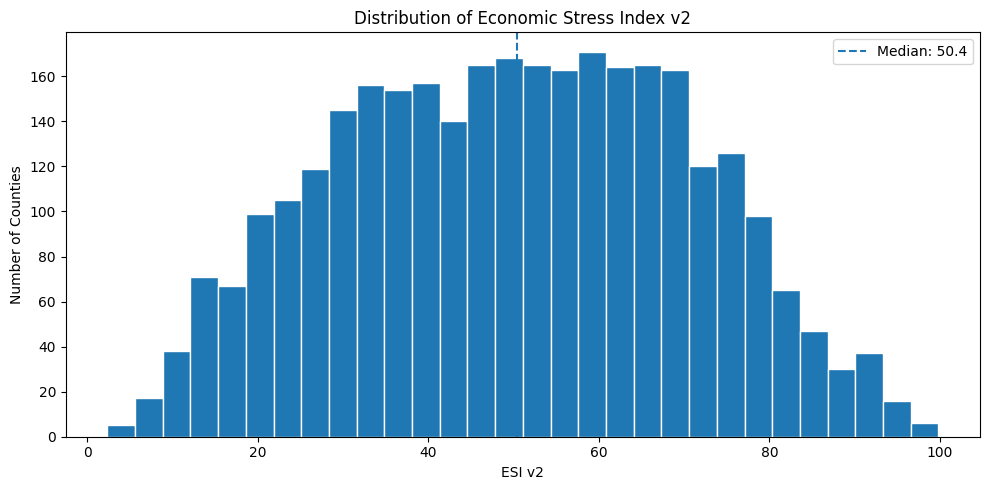

In [7]:
esi = df["ESI_C"].dropna()

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(esi, bins=30, edgecolor="white")

ax.axvline(
    esi.median(),
    linestyle="--",
    linewidth=1.5,
    label=f"Median: {esi.median():.1f}"
)

ax.set_title("Distribution of Economic Stress Index v2")
ax.set_xlabel("ESI v2")
ax.set_ylabel("Number of Counties")
ax.legend()

plt.tight_layout()
plt.show()

In [8]:
from scipy.stats import skew

print(f"Mean: {esi.mean():.2f}")
print(f"Median: {esi.median():.2f}")
print(f"Standard deviation: {esi.std():.2f}")
print(f"Skewness: {skew(esi):.3f}")
print(f"Minimum: {esi.min():.2f}")
print(f"Maximum: {esi.max():.2f}")

Mean: 50.03
Median: 50.38
Standard deviation: 20.32
Skewness: -0.005
Minimum: 2.38
Maximum: 99.81


### Initial Findings

ESI v2 is centered near 50 and exhibits an almost perfectly symmetric national distribution. Across the 3,142 counties and county equivalents with complete component data, the mean ESI is 50.03 and the median is 50.38. The distribution has a standard deviation of 20.32 and virtually no skew (−0.005), with observed scores ranging from 2.38 to 99.81.

Because ESI v2 combines three percentile-ranked component measures, a national center near 50 is expected. However, the composite ESI itself is not percentile-ranked; its resulting distribution reflects how poverty, prime-age nonwork, and severe housing burden co-occur across counties.

## 3. ESI Component Relationships

ESI v2 combines county percentile rankings for poverty, prime-age nonwork, and severe housing burden. Examining relationships among these components helps determine the extent to which they capture overlapping or distinct dimensions of county-level economic stress.

Correlations between each component and the composite ESI are also examined as a descriptive check on the constructed index. Because the component measures are used directly to calculate ESI v2, these correlations should not be interpreted as independent evidence of association.

In [9]:
component_fields = [
    "ESI_Poverty_Percentile",
    "ESI_NonWork_Percentile",
    "ESI_Housing_Percentile",
    "ESI_C"
]

component_corr = df[component_fields].corr(method="pearson")

component_corr.round(3)

,ESI_Poverty_Percentile,ESI_NonWork_Percentile,ESI_Housing_Percentile,ESI_C
ESI_Poverty_Percentile,1.000,0.713,0.017,0.819
ESI_NonWork_Percentile,0.713,1.000,-0.000,0.811
ESI_Housing_Percentile,0.017,-0.000,1.000,0.481
ESI_C,0.819,0.811,0.481,1.000


In [10]:
component_spearman = df[component_fields].corr(method="spearman")

component_spearman.round(3)

,ESI_Poverty_Percentile,ESI_NonWork_Percentile,ESI_Housing_Percentile,ESI_C
ESI_Poverty_Percentile,1.000,0.713,0.017,0.826
ESI_NonWork_Percentile,0.713,1.000,-0.000,0.813
ESI_Housing_Percentile,0.017,-0.000,1.000,0.461
ESI_C,0.826,0.813,0.461,1.000


### Component Relationship Findings

Poverty and prime-age nonwork percentiles are strongly positively correlated (r = 0.713), indicating substantial overlap in county rankings on these two dimensions of economic stress.

Severe housing burden, however, is essentially uncorrelated with both poverty (r = 0.017) and prime-age nonwork (r ≈ 0.000). This indicates that severe housing burden contributes a substantially different dimension to the composite index rather than reproducing the same geographic pattern captured by poverty and nonwork.

Correlations between the component measures and ESI v2 are high for poverty (r = 0.819) and prime-age nonwork (r = 0.811), and more moderate for severe housing burden (r = 0.481). These relationships should be interpreted in the context of index construction because all three measures are components of ESI v2 and are intentionally weighted within the composite.

Spearman rank correlations produced nearly identical relationships among the three component measures, indicating that the observed pattern is not dependent on Pearson's linear-association assumption. Severe housing burden remains essentially unrelated to poverty and prime-age nonwork even when the comparison is based on county rankings.

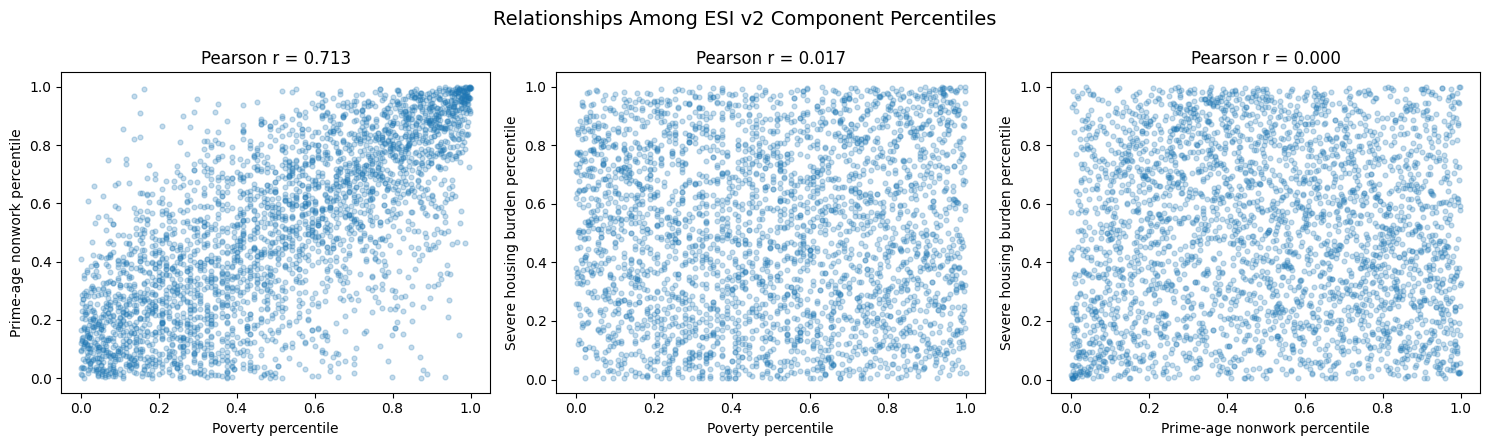

In [12]:
# Visualize pairwise relationships among ESI component percentiles

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

pairs = [
    (
        "ESI_Poverty_Percentile",
        "ESI_NonWork_Percentile",
        "Poverty percentile",
        "Prime-age nonwork percentile"
    ),
    (
        "ESI_Poverty_Percentile",
        "ESI_Housing_Percentile",
        "Poverty percentile",
        "Severe housing burden percentile"
    ),
    (
        "ESI_NonWork_Percentile",
        "ESI_Housing_Percentile",
        "Prime-age nonwork percentile",
        "Severe housing burden percentile"
    )
]

for ax, (x, y, xlabel, ylabel) in zip(axes, pairs):
    plot_df = df[[x, y]].dropna()

    r = plot_df[x].corr(plot_df[y])

    # Prevent extremely small values from displaying as -0.000
    if abs(r) < 0.0005:
        r = 0.0

    ax.scatter(
        plot_df[x],
        plot_df[y],
        alpha=0.25,
        s=12
    )

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(f"Pearson r = {r:.3f}")

fig.suptitle(
    "Relationships Among ESI v2 Component Percentiles",
    fontsize=14
)

plt.tight_layout()
plt.show()

## 4. Geographic Distribution of ESI v2

Geographic patterns in ESI v2 are examined using U.S. Census regions and divisions. In addition to comparing median ESI values, the analysis evaluates the concentration of counties in the upper tail of the national ESI distribution.

Counties at or above the national 80th percentile are classified as the highest-stress quintile, while counties at or above the 90th percentile are classified as the highest-stress decile. These thresholds provide a consistent national benchmark for evaluating whether high-ESI counties are disproportionately concentrated within particular geographic areas.

In [13]:
# Calculate national ESI thresholds

esi_80 = df["ESI_C"].quantile(0.80)
esi_90 = df["ESI_C"].quantile(0.90)

print(f"80th percentile ESI threshold: {esi_80:.2f}")
print(f"90th percentile ESI threshold: {esi_90:.2f}")

80th percentile ESI threshold: 68.92
90th percentile ESI threshold: 76.65


In [14]:
# Create upper-tail indicators for geographic analysis

df["ESI_Top_20"] = df["ESI_C"] >= esi_80
df["ESI_Top_10"] = df["ESI_C"] >= esi_90

print(f"Counties in highest-stress 20%: {df['ESI_Top_20'].sum():,}")
print(f"Counties in highest-stress 10%: {df['ESI_Top_10'].sum():,}")

Counties in highest-stress 20%: 629
Counties in highest-stress 10%: 315


In [15]:
region_summary = (
    df.dropna(subset=["ESI_C"])
      .groupby("Region")
      .agg(
          Counties=("ESI_C", "size"),
          Median_ESI=("ESI_C", "median"),
          Q1_ESI=("ESI_C", lambda x: x.quantile(0.25)),
          Q3_ESI=("ESI_C", lambda x: x.quantile(0.75)),
          Top_20_Count=("ESI_Top_20", "sum"),
          Top_10_Count=("ESI_Top_10", "sum")
      )
)

region_summary["Top_20_Pct"] = (
    region_summary["Top_20_Count"] / region_summary["Counties"] * 100
)

region_summary["Top_10_Pct"] = (
    region_summary["Top_10_Count"] / region_summary["Counties"] * 100
)

region_summary = region_summary[
    [
        "Counties",
        "Median_ESI",
        "Q1_ESI",
        "Q3_ESI",
        "Top_20_Count",
        "Top_20_Pct",
        "Top_10_Count",
        "Top_10_Pct"
    ]
].round(2)

region_summary.sort_values("Median_ESI", ascending=False)

,Counties,Median_ESI,Q1_ESI,Q3_ESI,Top_20_Count,Top_20_Pct,Top_10_Count,Top_10_Pct
Region,,,,,,,,
South,1421,61.75,47.88,72.98,474,33.36,243,17.10
Northeast,218,48.37,36.27,58.27,18,8.26,5,2.29
West,448,46.36,33.09,63.05,72,16.07,37,8.26
Midwest,1055,35.07,23.35,50.50,65,6.16,30,2.84


### Regional Findings

Economic stress is strongly geographically concentrated. The South has the highest median ESI (61.75), compared with 48.37 in the Northeast, 46.36 in the West, and 35.07 in the Midwest.

The concentration is especially apparent in the upper tail of the national distribution. Approximately 33.4% of Southern counties fall within the highest-stress national quintile, compared with a national benchmark of approximately 20%, while 17.1% fall within the highest-stress decile, compared with a national benchmark of approximately 10%. The Midwest shows the opposite pattern, with only 6.2% of counties in the highest-stress quintile and 2.8% in the highest-stress decile.

Regional differences extend beyond the extremes. The South's first-quartile ESI (47.88) is close to the Midwest's third-quartile ESI (50.50), indicating a broad shift in the distributions rather than a difference driven solely by a small number of high-ESI counties.

The Northeast and West have relatively similar median ESI values, but the West has substantially greater representation in the upper national tail. This suggests greater within-region variation and warrants further analysis at the Census-division level.

### Census Division Analysis

Regional results show substantial geographic differences in ESI v2, including a strong concentration of high-ESI counties in the South and greater upper-tail representation in the West than its median alone suggests. Census divisions provide a more detailed geographic view and help identify whether these regional patterns are broadly distributed or concentrated within particular parts of each region.

In [16]:
division_summary = (
    df.dropna(subset=["ESI_C"])
      .groupby(["Region", "Census_Division"])
      .agg(
          Counties=("ESI_C", "size"),
          Median_ESI=("ESI_C", "median"),
          Q1_ESI=("ESI_C", lambda x: x.quantile(0.25)),
          Q3_ESI=("ESI_C", lambda x: x.quantile(0.75)),
          Top_20_Count=("ESI_Top_20", "sum"),
          Top_10_Count=("ESI_Top_10", "sum")
      )
)

division_summary["Top_20_Pct"] = (
    division_summary["Top_20_Count"]
    / division_summary["Counties"] * 100
)

division_summary["Top_10_Pct"] = (
    division_summary["Top_10_Count"]
    / division_summary["Counties"] * 100
)

division_summary = division_summary[
    [
        "Counties",
        "Median_ESI",
        "Q1_ESI",
        "Q3_ESI",
        "Top_20_Count",
        "Top_20_Pct",
        "Top_10_Count",
        "Top_10_Pct"
    ]
].round(2)

division_summary.sort_values(
    "Median_ESI",
    ascending=False
)

Counties  Median_ESI  Q1_ESI  Q3_ESI  \
Region    Census_Division                                            
South     East South Central       364       64.86   52.79   74.26   
          West South Central       469       61.57   46.26   72.64   
          South Atlantic           588       60.18   45.67   71.81   
West      Pacific                  167       52.98   40.04   66.14   
Northeast Middle Atlantic          150       52.04   39.31   61.43   
Midwest   East North Central       437       42.09   28.96   55.38   
West      Mountain                 281       40.62   30.66   60.17   
Northeast New England               68       39.49   32.08   49.96   
Midwest   West North Central       618       30.95   20.37   45.52   

                              Top_20_Count  Top_20_Pct  Top_10_Count  \
Region    Census_Division                                              
South     East South Central           139       38.19            72   
          West South Central           155       33.05            76   
          South Atlantic               180       30.61            95   
West      Pacific                       35       20.96            16   
Northeast Middle Atlantic               17       11.33             5   
Midwest   East North Central            36        8.24            19   
West      Mountain                      37       13.17            21   
Northeast New England                    1        1.47             0   
Midwest   West North Central            29        4.69            11   

                              Top_10_Pct  
Region    Census_Division                 
South     East South Central       19.78  
          West South Central       16.20  
          South Atlantic           16.16  
West      Pacific                   9.58  
Northeast Middle Atlantic           3.33  
Midwest   East North Central        4.35  
West      Mountain                  7.47  
Northeast New England               0.00  
Midwest   West North Central        1.78

### Census Division Findings

The regional concentration of economic stress is not attributable to a single Southern subregion. All three Southern Census divisions have the highest median ESI values among the nine divisions: East South Central (64.86), West South Central (61.57), and South Atlantic (60.18). Each also has more than 30% of its counties in the national highest-stress quintile and more than 16% in the highest-stress decile.

East South Central shows the strongest concentration, with 38.2% of counties in the highest-stress quintile and 19.8% in the highest-stress decile. Its first-quartile ESI (52.79) exceeds the third-quartile ESI of West North Central (45.52), illustrating a substantial difference in the locations of the two distributions.

West North Central has the lowest median ESI (30.95), with 4.7% of counties in the highest-stress quintile and 1.8% in the highest-stress decile. New England also has relatively low upper-tail representation: only one of its 68 counties falls within the highest-stress quintile, and none falls within the highest-stress decile.

Division-level analysis also reveals variation concealed by broader regional summaries. The Pacific division has a median ESI of 52.98 compared with 40.62 in the Mountain division, while the Middle Atlantic median (52.04) substantially exceeds New England (39.49). These differences indicate that Census division provides important additional geographic context beyond the four-region classification.

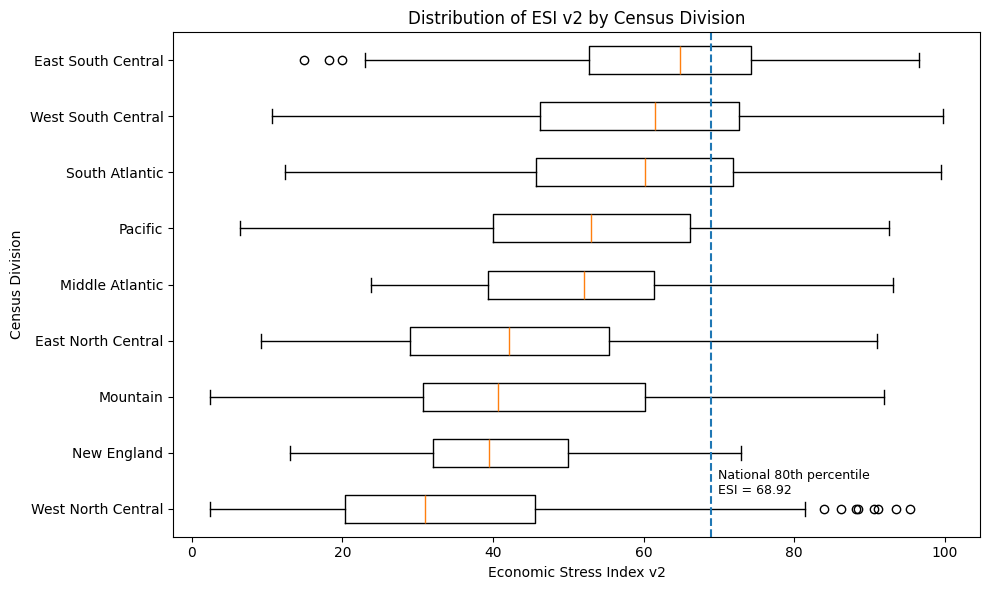

In [18]:
# Order Census divisions by median ESI
division_order = (
    df.dropna(subset=["ESI_C"])
      .groupby("Census_Division")["ESI_C"]
      .median()
      .sort_values(ascending=True)
      .index
)

plot_data = [
    df.loc[
        (df["Census_Division"] == division) & df["ESI_C"].notna(),
        "ESI_C"
    ]
    for division in division_order
]

fig, ax = plt.subplots(figsize=(10, 6))

ax.boxplot(
    plot_data,
    vert=False,
    tick_labels=division_order,
    showfliers=True
)

# National highest-stress quintile threshold
ax.axvline(

    esi_80,

    linestyle="--",

    linewidth=1.5

)

ax.text(

    esi_80 + 1,

    1.2,

    f"National 80th percentile\nESI = {esi_80:.2f}",

    fontsize=9,

    va="bottom"

)

ax.set_title("Distribution of ESI v2 by Census Division")

ax.set_xlabel("Economic Stress Index v2")

ax.set_ylabel("Census Division")

plt.tight_layout()

plt.show()

## 5. Anatomy of Regional Economic Stress

The preceding analysis identifies substantial geographic differences in ESI v2, but a composite score alone does not reveal which underlying conditions produce those differences. Because ESI v2 combines poverty, prime-age nonwork, and severe housing burden, counties and regions with similar composite scores may reflect different forms of economic stress.

This section examines the component structure of ESI across Census divisions. Component percentiles are compared on their common national ranking scale to identify whether elevated divisional ESI values reflect broadly elevated stress across multiple dimensions or concentration in particular components.

In [19]:
division_components = (
    df.dropna(
        subset=[
            "ESI_C",
            "ESI_Poverty_Percentile",
            "ESI_NonWork_Percentile",
            "ESI_Housing_Percentile"
        ]
    )
    .groupby(["Region", "Census_Division"])
    .agg(
        Counties=("ESI_C", "size"),
        Poverty_Median=("ESI_Poverty_Percentile", "median"),
        NonWork_Median=("ESI_NonWork_Percentile", "median"),
        Housing_Median=("ESI_Housing_Percentile", "median"),
        Median_ESI=("ESI_C", "median")
    )
    .round(3)
)

division_components.sort_values(
    "Median_ESI",
    ascending=False
)

Counties  Poverty_Median  NonWork_Median  \
Region    Census_Division                                                
South     East South Central       364           0.759           0.753   
          West South Central       469           0.712           0.680   
          South Atlantic           588           0.629           0.617   
West      Pacific                  167           0.453           0.524   
Northeast Middle Atlantic          150           0.408           0.434   
Midwest   East North Central       437           0.388           0.393   
West      Mountain                 281           0.408           0.412   
Northeast New England               68           0.192           0.244   
Midwest   West North Central       618           0.336           0.180   

                              Housing_Median  Median_ESI  
Region    Census_Division                                 
South     East South Central           0.485      64.856  
          West South Central           0.439      61.571  
          South Atlantic               0.615      60.181  
West      Pacific                      0.720      52.980  
Northeast Middle Atlantic              0.738      52.039  
Midwest   East North Central           0.478      42.088  
West      Mountain                     0.458      40.625  
Northeast New England                  0.730      39.493  
Midwest   West North Central           0.324      30.950

### Component Profile Findings

Census divisions with similar or moderately close ESI values can exhibit substantially different underlying component profiles, demonstrating that the composite index captures more than one configuration of county-level economic stress.

East South Central and West South Central are characterized primarily by elevated poverty and prime-age nonwork rankings, while their median severe housing burden rankings remain near or below the national county midpoint. South Atlantic differs: its median county ranks above the national midpoint across all three ESI components, producing a more broadly elevated stress profile.

A different pattern appears in the Pacific and Middle Atlantic divisions. Their median poverty and nonwork rankings are near or below the national midpoint, while severe housing burden ranks substantially higher, at the 72nd and 74th national percentiles, respectively.

New England provides the clearest contrast. Its median county ranks relatively low nationally in poverty (19th percentile) and prime-age nonwork (24th percentile), but high in severe housing burden (73rd percentile). West North Central, by comparison, has median rankings below the national midpoint across all three components.

These results demonstrate why ESI should be interpreted alongside its component measures. Similar composite values do not necessarily represent the same underlying economic conditions, and geographic differences in ESI reflect distinct combinations of poverty, labor-market detachment, and housing burden.

### Component Profiles Across Census Divisions

Median component percentiles provide a common scale for comparing the composition of economic stress across Census divisions. The national county midpoint (0.50) is shown as a reference, allowing each division's typical poverty, prime-age nonwork, and severe housing burden rankings to be compared directly.

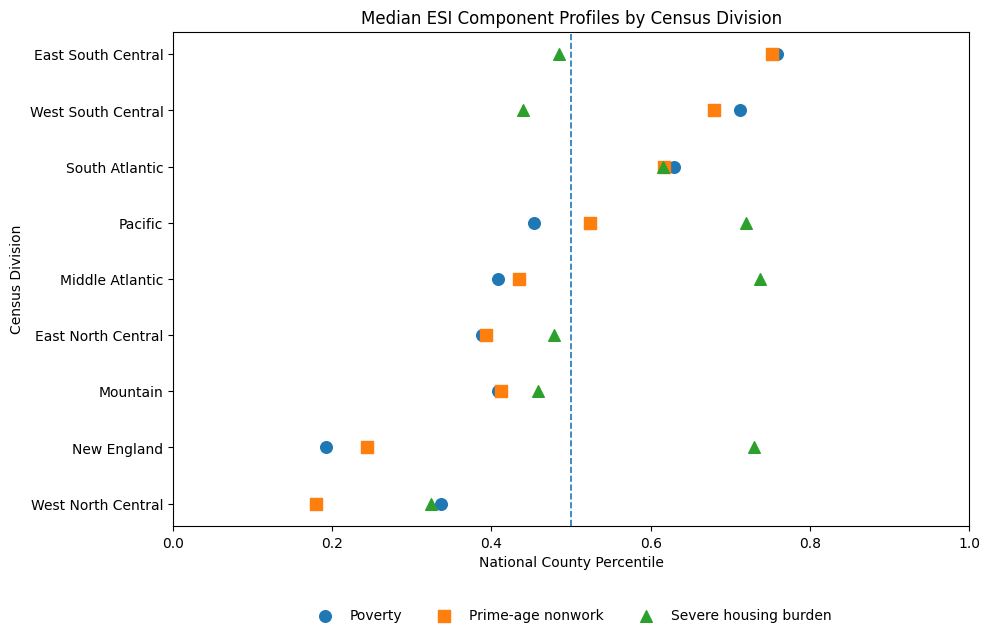

In [20]:
# Prepare median component profiles in ESI order

profile_df = (
    division_components
    .reset_index()
    .sort_values("Median_ESI", ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 6.5))

y = np.arange(len(profile_df))

ax.scatter(
    profile_df["Poverty_Median"],
    y,
    s=70,
    label="Poverty"
)

ax.scatter(
    profile_df["NonWork_Median"],
    y,
    s=70,
    marker="s",
    label="Prime-age nonwork"
)

ax.scatter(
    profile_df["Housing_Median"],
    y,
    s=70,
    marker="^",
    label="Severe housing burden"
)

# National county midpoint
ax.axvline(
    0.50,
    linestyle="--",
    linewidth=1.2
)

ax.set_yticks(y)
ax.set_yticklabels(profile_df["Census_Division"])

ax.set_xlim(0, 1)

ax.set_title("Median ESI Component Profiles by Census Division")
ax.set_xlabel("National County Percentile")
ax.set_ylabel("Census Division")

ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, -0.22),
    ncol=3,
    frameon=False
)

plt.tight_layout()
plt.show()

## 6. Economic Stress and Food Insecurity

Food insecurity provides an external measure with which to examine the broader relevance of ESI v2. Food insecurity is not used in the construction of the index, allowing its relationship with ESI and the individual ESI components to be evaluated independently.

Before examining these relationships, the distribution of county-level food insecurity is assessed to establish its central tendency, spread, range, and shape.

In [21]:
fi = df["Food_Insecurity_Rate"].dropna()

print(f"Complete observations: {len(fi):,}")
print(f"Mean: {fi.mean():.3%}")
print(f"Median: {fi.median():.3%}")
print(f"Standard deviation: {fi.std():.3%}")
print(f"Skewness: {fi.skew():.3f}")
print(f"Minimum: {fi.min():.3%}")
print(f"Maximum: {fi.max():.3%}")

Complete observations: 3,142
Mean: 16.352%
Median: 16.100%
Standard deviation: 3.954%
Skewness: 0.533
Minimum: 5.800%
Maximum: 37.100%


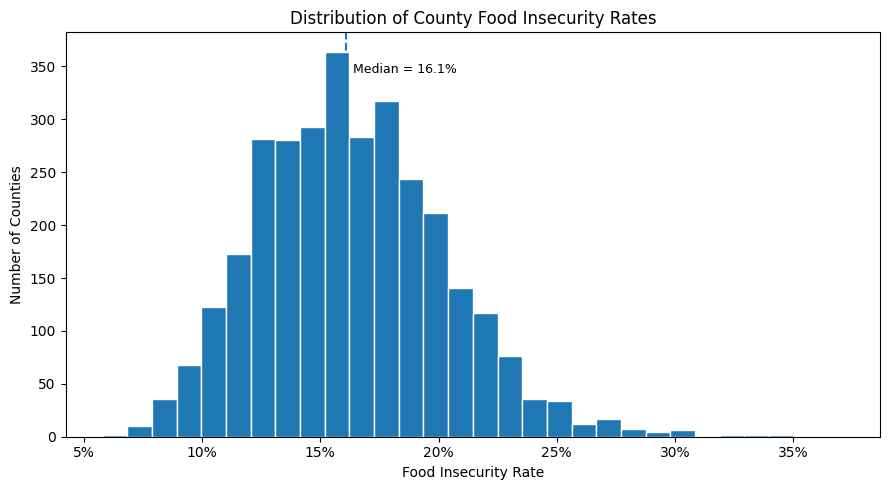

In [22]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    fi,
    bins=30,
    edgecolor="white"
)

ax.axvline(
    fi.median(),
    linestyle="--",
    linewidth=1.5
)

ax.text(
    fi.median() + 0.003,
    ax.get_ylim()[1] * 0.90,
    f"Median = {fi.median():.1%}",
    fontsize=9
)

ax.set_title("Distribution of County Food Insecurity Rates")
ax.set_xlabel("Food Insecurity Rate")
ax.set_ylabel("Number of Counties")

# Display x-axis as percentages
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:.0%}")
)

plt.tight_layout()
plt.show()

### Food Insecurity Distribution

County food insecurity rates are moderately right-skewed (skewness = 0.533), with a mean of 16.35% and median of 16.10%. Rates range from 5.8% to 37.1%, indicating substantial variation across counties. The relatively close mean and median suggest that the right tail does not strongly distort the center of the distribution, although a smaller number of counties experience substantially higher food insecurity rates.

In [23]:
fi_relationship_vars = [
    "Food_Insecurity_Rate",
    "ESI_C",
    "ESI_Poverty_Percentile",
    "ESI_NonWork_Percentile",
    "ESI_Housing_Percentile"
]

fi_corr = (
    df[fi_relationship_vars]
    .dropna()
    .corr(method="pearson")
)

fi_corr.round(3)

,Food_Insecurity_Rate,ESI_C,ESI_Poverty_Percentile,ESI_NonWork_Percentile,ESI_Housing_Percentile
Food_Insecurity_Rate,1.000,0.652,0.761,0.651,-0.035
ESI_C,0.652,1.000,0.819,0.811,0.481
ESI_Poverty_Percentile,0.761,0.819,1.000,0.713,0.016
ESI_NonWork_Percentile,0.651,0.811,0.713,1.000,-0.000
ESI_Housing_Percentile,-0.035,0.481,0.016,-0.000,1.000


In [24]:
fi_correlations = (
    fi_corr["Food_Insecurity_Rate"]
    .drop("Food_Insecurity_Rate")
    .sort_values(ascending=False)
    .to_frame(name="Pearson_r")
)

fi_correlations.round(3)

,Pearson_r
ESI_Poverty_Percentile,0.761
ESI_C,0.652
ESI_NonWork_Percentile,0.651
ESI_Housing_Percentile,-0.035


### Relationship with Food Insecurity

ESI v2 is strongly positively associated with county food insecurity (Pearson r = 0.652), providing evidence that the independently constructed economic stress index captures conditions meaningfully related to an important measure of material hardship.

The relationship is not equally distributed across ESI components. Poverty percentile has the strongest association with food insecurity (r = 0.761), followed by prime-age nonwork percentile (r = 0.651). Severe housing burden percentile has essentially no national linear association with county food insecurity (r = -0.035).

These results reinforce the distinction between a multidimensional economic stress index and a model designed specifically to predict food insecurity. Poverty alone is more strongly associated with food insecurity than the composite ESI, while housing burden contributes a largely distinct dimension of economic stress that is not captured by the food insecurity relationship.

Accordingly, ESI should not be interpreted as an optimized predictor of food insecurity. Its purpose is broader: to summarize multiple dimensions of county economic stress while preserving component-level differences that may characterize different forms of hardship across places.

In [25]:
raw_fi_vars = [
    "Food_Insecurity_Rate",
    "Poverty_All_Pct",
    "Prime_Age_Did_Not_Work_Pct",
    "Severe_Burden_Pct",
    "Median_Household_Income",
    "ESI_C"
]

raw_fi_corr = (
    df[raw_fi_vars]
    .dropna()
    .corr(method="pearson")
)

raw_fi_relationships = (
    raw_fi_corr["Food_Insecurity_Rate"]
    .drop("Food_Insecurity_Rate")
    .sort_values(ascending=False)
    .to_frame(name="Pearson_r")
)

raw_fi_relationships.round(3)

,Pearson_r
Poverty_All_Pct,0.740
ESI_C,0.652
Prime_Age_Did_Not_Work_Pct,0.590
Severe_Burden_Pct,-0.014
Median_Household_Income,-0.692


Severe housing burden again shows essentially no national linear relationship with food insecurity (r = -0.014). This should not be interpreted as evidence that housing burden is unimportant to economic stress. Rather, housing burden captures a dimension of county economic conditions that is largely distinct from poverty, prime-age nonwork, and food insecurity at the national level.

This distinction is especially visible geographically. New England counties rank relatively low nationally in poverty and prime-age nonwork but substantially higher in severe housing burden. Excluding housing would therefore understate an important form of economic pressure in places whose stress is not primarily characterized by poverty or labor-market detachment.

In [26]:
spearman_vars = [
    "Food_Insecurity_Rate",
    "Poverty_All_Pct",
    "Prime_Age_Did_Not_Work_Pct",
    "Severe_Burden_Pct",
    "Median_Household_Income",
    "ESI_C"
]

spearman_corr = (
    df[spearman_vars]
    .dropna()
    .corr(method="spearman")
)

spearman_relationships = (
    spearman_corr["Food_Insecurity_Rate"]
    .drop("Food_Insecurity_Rate")
    .sort_values(ascending=False)
    .to_frame(name="Spearman_rho")
)

spearman_relationships.round(3)

,Spearman_rho
Poverty_All_Pct,0.781
ESI_C,0.672
Prime_Age_Did_Not_Work_Pct,0.667
Severe_Burden_Pct,-0.039
Median_Household_Income,-0.752


### Correlation Robustness Check

Spearman rank correlations produced the same substantive pattern as the Pearson correlations. Poverty remained most strongly positively associated with food insecurity (ρ = 0.781), followed by ESI v2 (ρ = 0.672) and prime-age nonwork (ρ = 0.667), while median household income remained strongly negatively associated (ρ = -0.752). Severe housing burden again showed essentially no national association (ρ = -0.039).

The consistency of the Pearson and Spearman results indicates that the principal findings are robust to correlation method.

In [27]:
from scipy.stats import linregress

reg_df = df[
    ["ESI_C", "Food_Insecurity_Rate"]
].dropna()

result = linregress(
    reg_df["ESI_C"],
    reg_df["Food_Insecurity_Rate"]
)

r_squared = result.rvalue ** 2

print(f"Observations: {len(reg_df):,}")
print(f"Slope: {result.slope:.6f}")
print(f"Intercept: {result.intercept:.6f}")
print(f"Pearson r: {result.rvalue:.3f}")
print(f"R-squared: {r_squared:.3f}")
print(f"P-value: {result.pvalue:.3e}")
print(f"Standard error: {result.stderr:.6f}")

Observations: 3,142
Slope: 0.001269
Intercept: 0.100042
Pearson r: 0.652
R-squared: 0.425
P-value: 0.000e+00
Standard error: 0.000026


In [28]:
slope_percentage_points = result.slope * 100

print(
    f"Change in food insecurity rate per 1-point increase in ESI: "
    f"{slope_percentage_points:.3f} percentage points"
)

print(
    f"Change per 10-point increase in ESI: "
    f"{slope_percentage_points * 10:.2f} percentage points"
)

Change in food insecurity rate per 1-point increase in ESI: 0.127 percentage points
Change per 10-point increase in ESI: 1.27 percentage points


### Simple Linear Regression: ESI v2 and Food Insecurity

A simple linear regression was used to examine the relationship between ESI v2 and county food insecurity across 3,142 counties with complete observations. ESI v2 was strongly positively associated with food insecurity (r = 0.652), and the model explained approximately 42.5% of the observed variation in county food insecurity (R² = 0.425, p < .001).

The estimated slope was 0.001269, meaning that each one-point increase in ESI was associated with an approximately 0.127-percentage-point increase in food insecurity. Expressed more interpretably, a 10-point increase in ESI was associated with an estimated 1.27-percentage-point increase in the county food insecurity rate.

This bivariate relationship should not be interpreted causally. ESI summarizes multiple dimensions of county economic conditions, and food insecurity is influenced by additional economic, demographic, policy, and geographic factors not represented in this simple model.

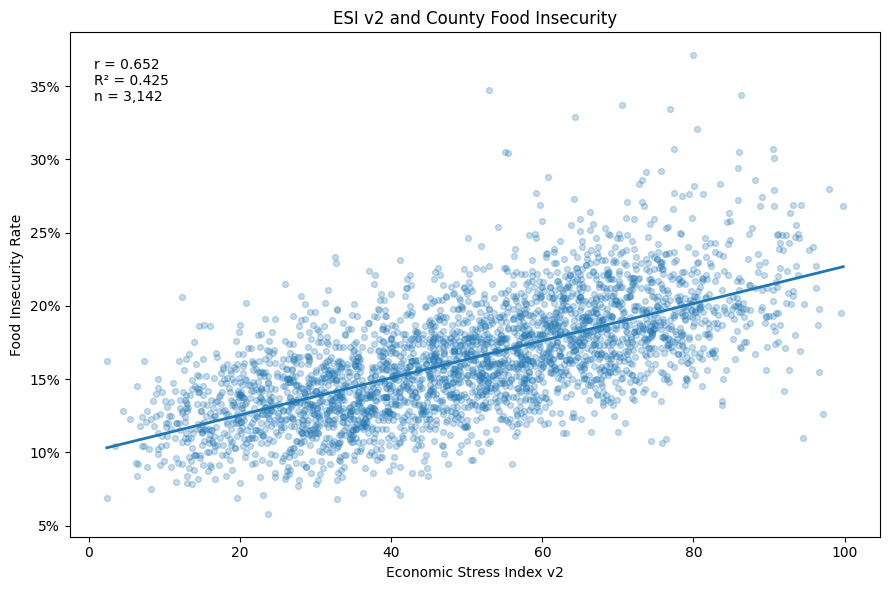

In [29]:
# Scatterplot with fitted regression line

fig, ax = plt.subplots(figsize=(9, 6))

# County observations
ax.scatter(
    reg_df["ESI_C"],
    reg_df["Food_Insecurity_Rate"],
    alpha=0.25,
    s=18
)

# Regression line
x_line = np.linspace(
    reg_df["ESI_C"].min(),
    reg_df["ESI_C"].max(),
    200
)

y_line = result.intercept + result.slope * x_line

ax.plot(
    x_line,
    y_line,
    linewidth=2
)

# Labels and formatting
ax.set_title("ESI v2 and County Food Insecurity")
ax.set_xlabel("Economic Stress Index v2")
ax.set_ylabel("Food Insecurity Rate")

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

# Model annotation
ax.text(
    0.03,
    0.95,
    f"r = {result.rvalue:.3f}\n"
    f"R² = {r_squared:.3f}\n"
    f"n = {len(reg_df):,}",
    transform=ax.transAxes,
    va="top",
    fontsize=10
)

plt.tight_layout()
plt.show()

### Regression Diagnostic

Because the ESI–food insecurity scatterplot suggests that variation in food insecurity may increase at higher levels of economic stress, residuals are examined against fitted values. This diagnostic helps assess whether the variability around the regression line remains approximately constant across the range of predicted food insecurity.

In [30]:
reg_df = reg_df.copy()

reg_df["Fitted_FI"] = (
    result.intercept
    + result.slope * reg_df["ESI_C"]
)

reg_df["Residual"] = (
    reg_df["Food_Insecurity_Rate"]
    - reg_df["Fitted_FI"]
)

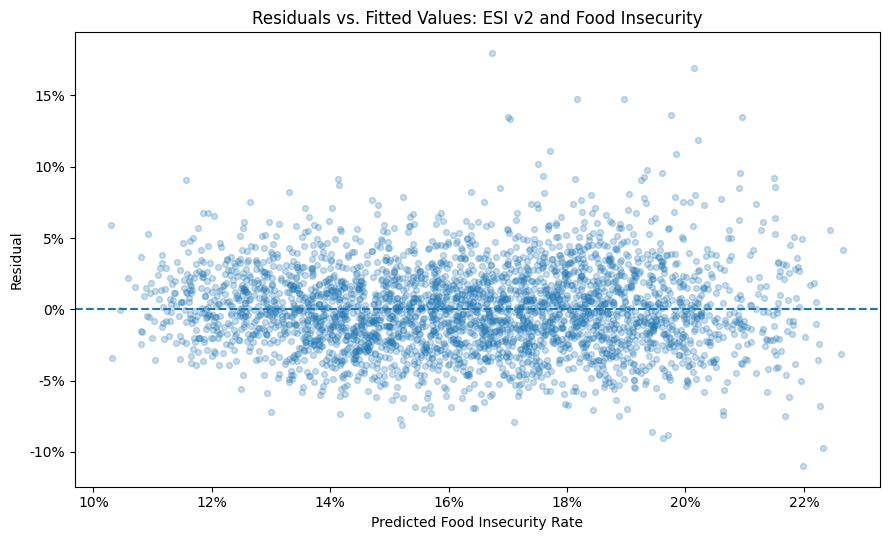

In [31]:
fig, ax = plt.subplots(figsize=(9, 5.5))

ax.scatter(
    reg_df["Fitted_FI"],
    reg_df["Residual"],
    alpha=0.25,
    s=18
)

# Zero-residual reference line
ax.axhline(
    0,
    linestyle="--",
    linewidth=1.5
)

ax.set_title("Residuals vs. Fitted Values: ESI v2 and Food Insecurity")
ax.set_xlabel("Predicted Food Insecurity Rate")
ax.set_ylabel("Residual")

ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:.0%}")
)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

plt.tight_layout()
plt.show()

### Regression Diagnostic Findings

The residual plot shows observations generally centered around zero across the fitted range, with no strong curvature suggesting a major departure from the linear form. Residual dispersion appears to increase somewhat at higher predicted food insecurity rates, indicating possible non-constant variance.

Several counties also exhibit substantially higher food insecurity than predicted by ESI alone. These observations reinforce that, although ESI explains a meaningful portion of county-level variation in food insecurity, additional factors contribute to particularly high food insecurity outcomes.

In [32]:
# Regional ESI–food insecurity relationship

regional_fi = (
    df.dropna(subset=["ESI_C", "Food_Insecurity_Rate"])
    .groupby("Region")
    .apply(
        lambda g: pd.Series({
            "Counties": len(g),
            "Median_ESI": g["ESI_C"].median(),
            "Median_FI": g["Food_Insecurity_Rate"].median(),
            "Pearson_r": g["ESI_C"].corr(g["Food_Insecurity_Rate"])
        }),
        include_groups=False
    )
    .sort_values("Median_ESI", ascending=False)
)

regional_fi["Counties"] = regional_fi["Counties"].astype(int)

regional_fi.round({
    "Median_ESI": 2,
    "Median_FI": 3,
    "Pearson_r": 3
})

,Counties,Median_ESI,Median_FI,Pearson_r
Region,,,,
South,1421,61.75,0.183,0.532
Northeast,218,48.37,0.128,0.615
West,448,46.36,0.156,0.608
Midwest,1055,35.07,0.146,0.661


### Regional ESI and Food Insecurity Relationships

The positive relationship between ESI v2 and food insecurity persists within each major U.S. Census region, indicating that the national association is not solely the result of differences between regions. Pearson correlations range from 0.532 in the South to 0.661 in the Midwest, with similarly substantial relationships in the Northeast (r = 0.615) and West (r = 0.608).

Regional levels nevertheless differ considerably. The South has both the highest median ESI (61.75) and highest median food insecurity rate (18.3%), while the Midwest has the lowest median ESI (35.07) but the strongest within-region ESI–food insecurity correlation. The Northeast and West have relatively similar median ESI values (48.37 and 46.36) and similar within-region correlations, yet their median food insecurity rates differ substantially (12.8% and 15.6%, respectively).

These results suggest that ESI captures economic conditions meaningfully associated with food insecurity across regions while also preserving regional differences in the composition and consequences of economic stress. ESI should therefore be interpreted as a multidimensional measure of economic stress rather than as a food-insecurity prediction score.

In [33]:
division_fi = (
    df.dropna(
        subset=["ESI_C", "Food_Insecurity_Rate", "Census_Division"]
    )
    .groupby(["Region", "Census_Division"])
    .apply(
        lambda g: pd.Series({
            "Counties": len(g),
            "Median_ESI": g["ESI_C"].median(),
            "Median_FI": g["Food_Insecurity_Rate"].median(),
            "Pearson_r": g["ESI_C"].corr(g["Food_Insecurity_Rate"])
        }),
        include_groups=False
    )
    .sort_values("Median_ESI", ascending=False)
)

division_fi["Counties"] = division_fi["Counties"].astype(int)

division_fi.round({
    "Median_ESI": 2,
    "Median_FI": 3,
    "Pearson_r": 3
})

Counties  Median_ESI  Median_FI  Pearson_r
Region    Census_Division                                               
South     East South Central       364       64.86      0.193      0.657
          West South Central       469       61.57      0.200      0.479
          South Atlantic           588       60.18      0.162      0.642
West      Pacific                  167       52.98      0.157      0.419
Northeast Middle Atlantic          150       52.04      0.129      0.603
Midwest   East North Central       437       42.09      0.150      0.715
West      Mountain                 281       40.62      0.154      0.715
Northeast New England               68       39.49      0.128      0.767
Midwest   West North Central       618       30.95      0.141      0.640

### Census Division Differences

The positive relationship between ESI v2 and food insecurity persists within all nine Census divisions, but its strength varies substantially. Within-division Pearson correlations range from 0.419 in the Pacific division to 0.767 in New England.

The three Southern divisions illustrate important variation hidden by the broader regional grouping. East South Central has the highest median ESI (64.86) and a strong ESI–food insecurity relationship (r = 0.657), while West South Central has the highest median food insecurity rate (20.0%) but a weaker within-division relationship (r = 0.479). South Atlantic counties have similarly elevated median ESI (60.18) but a lower median food insecurity rate (16.2%).

Differences also appear among divisions where housing burden contributes strongly to the ESI profile. New England has relatively low median ESI (39.49) and food insecurity (12.8%) but the strongest within-division ESI–food insecurity association (r = 0.767), while the Pacific division has higher median ESI (52.98), higher food insecurity (15.7%), and the weakest association (r = 0.419).

These findings demonstrate that the national ESI–food insecurity relationship masks meaningful geographic variation. Economic stress is multidimensional, and similar composite scores may represent different combinations of poverty, labor-market detachment, and housing burden across places.

## 7. Food Insecurity Across U.S. Counties

The preceding analysis used county food insecurity as an external outcome for evaluating the relationship between ESI v2 and material hardship. This section examines food insecurity as an analytical subject in its own right.

The analysis evaluates the geographic distribution of food insecurity, differences between overall and child food insecurity, metro and nonmetro patterns, economic relationships, and counties whose observed food insecurity differs substantially from the level predicted by ESI v2.

In [34]:
# National food insecurity thresholds

fi_80 = df["Food_Insecurity_Rate"].quantile(0.80)
fi_90 = df["Food_Insecurity_Rate"].quantile(0.90)

print(f"80th percentile FI threshold: {fi_80:.1%}")
print(f"90th percentile FI threshold: {fi_90:.1%}")

80th percentile FI threshold: 19.6%
90th percentile FI threshold: 21.5%


In [35]:
df["FI_Top_20"] = df["Food_Insecurity_Rate"] >= fi_80
df["FI_Top_10"] = df["Food_Insecurity_Rate"] >= fi_90

print(f"Counties in highest-FI 20%: {df['FI_Top_20'].sum():,}")
print(f"Counties in highest-FI 10%: {df['FI_Top_10'].sum():,}")

Counties in highest-FI 20%: 630
Counties in highest-FI 10%: 316


In [36]:
fi_division_summary = (
    df.dropna(subset=["Food_Insecurity_Rate"])
      .groupby(["Region", "Census_Division"])
      .agg(
          Counties=("Food_Insecurity_Rate", "size"),
          Median_FI=("Food_Insecurity_Rate", "median"),
          Q1_FI=("Food_Insecurity_Rate", lambda x: x.quantile(0.25)),
          Q3_FI=("Food_Insecurity_Rate", lambda x: x.quantile(0.75)),
          Top_20_Count=("FI_Top_20", "sum"),
          Top_10_Count=("FI_Top_10", "sum")
      )
)

fi_division_summary["Top_20_Pct"] = (
    fi_division_summary["Top_20_Count"]
    / fi_division_summary["Counties"] * 100
)

fi_division_summary["Top_10_Pct"] = (
    fi_division_summary["Top_10_Count"]
    / fi_division_summary["Counties"] * 100
)

fi_division_summary = fi_division_summary[
    [
        "Counties",
        "Median_FI",
        "Q1_FI",
        "Q3_FI",
        "Top_20_Count",
        "Top_20_Pct",
        "Top_10_Count",
        "Top_10_Pct"
    ]
]

fi_division_summary.sort_values(
    "Median_FI",
    ascending=False
).round(3)

Counties  Median_FI  Q1_FI  Q3_FI  Top_20_Count  \
Region    Census_Division                                                       
South     West South Central       469      0.200  0.178  0.223           263   
          East South Central       364      0.193  0.176  0.212           174   
          South Atlantic           588      0.162  0.138  0.181            74   
West      Pacific                  167      0.157  0.136  0.172            13   
          Mountain                 281      0.154  0.132  0.176            35   
Midwest   East North Central       437      0.150  0.134  0.169            25   
          West North Central       618      0.141  0.120  0.166            45   
Northeast Middle Atlantic          150      0.129  0.119  0.146             1   
          New England               68      0.128  0.116  0.152             0   

                              Top_20_Pct  Top_10_Count  Top_10_Pct  
Region    Census_Division                                           
South     West South Central      56.077           156      33.262  
          East South Central      47.802            80      21.978  
          South Atlantic          12.585            28       4.762  
West      Pacific                  7.784             5       2.994  
          Mountain                12.456            18       6.406  
Midwest   East North Central       5.721             6       1.373  
          West North Central       7.282            22       3.560  
Northeast Middle Atlantic          0.667             1       0.667  
          New England              0.000             0       0.000

### Geographic Concentration of Food Insecurity

County food insecurity is strongly concentrated geographically. Nationally, the 80th-percentile threshold is 19.6% and the 90th-percentile threshold is 21.5%, but counties exceeding these thresholds are distributed very unevenly across Census divisions.

West South Central has the highest median food insecurity rate (20.0%), with 56.1% of its counties in the highest national quintile and 33.3% in the highest decile. East South Central shows similarly elevated conditions: its median food insecurity rate is 19.3%, with 47.8% of counties in the highest quintile and 22.0% in the highest decile.

The concentration drops sharply in South Atlantic despite that division's similarly elevated median ESI. Only 12.6% of South Atlantic counties fall in the highest national food-insecurity quintile and 4.8% in the highest decile. This divergence further demonstrates that ESI and food insecurity measure related but distinct dimensions of county economic conditions.

At the opposite end of the distribution, no New England county falls within the highest national food-insecurity quintile or decile. Only one Middle Atlantic county exceeds each threshold. These comparatively low food-insecurity levels coexist with the elevated housing-burden profiles previously observed in these divisions, reinforcing the importance of retaining housing burden as a distinct dimension of ESI.

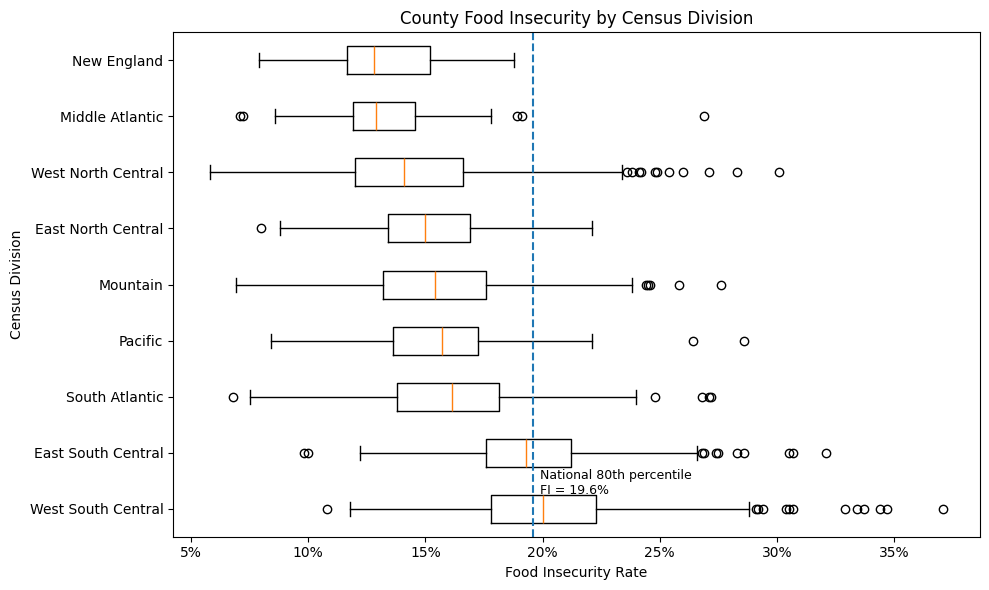

In [37]:
# Order divisions by median food insecurity, highest to lowest
division_order_fi = (
    df.groupby("Census_Division")["Food_Insecurity_Rate"]
      .median()
      .sort_values(ascending=False)
      .index
)

fig, ax = plt.subplots(figsize=(10, 6))

data_by_division = [
    df.loc[
        df["Census_Division"] == division,
        "Food_Insecurity_Rate"
    ].dropna()
    for division in division_order_fi
]

ax.boxplot(
    data_by_division,
    vert=False,
    tick_labels=division_order_fi,
    showfliers=True
)

# National 80th-percentile threshold
ax.axvline(
    fi_80,
    linestyle="--",
    linewidth=1.5
)

ax.text(
    fi_80 + 0.003,
    1.2,
    f"National 80th percentile\nFI = {fi_80:.1%}",
    fontsize=9,
    va="bottom"
)

ax.set_title("County Food Insecurity by Census Division")
ax.set_xlabel("Food Insecurity Rate")
ax.set_ylabel("Census Division")

ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:.0%}")
)

plt.tight_layout()
plt.show()

### Child Food Insecurity

Child food insecurity is examined separately from overall food insecurity because the prevalence and geographic distribution of food insecurity among children may differ from the pattern observed across the total population. The analysis evaluates both the national distribution of child food insecurity and its concentration across Census divisions.

In [38]:
child_fi = df["Child_Food_Insecurity_Rate"].dropna()

print(f"Complete observations: {len(child_fi):,}")
print(f"Mean: {child_fi.mean():.3%}")
print(f"Median: {child_fi.median():.3%}")
print(f"Standard deviation: {child_fi.std():.3%}")
print(f"Skewness: {child_fi.skew():.3f}")
print(f"Minimum: {child_fi.min():.3%}")
print(f"Maximum: {child_fi.max():.3%}")

child_fi_80 = child_fi.quantile(0.80)
child_fi_90 = child_fi.quantile(0.90)

print()
print(f"80th percentile child FI threshold: {child_fi_80:.1%}")
print(f"90th percentile child FI threshold: {child_fi_90:.1%}")

Complete observations: 3,142
Mean: 22.460%
Median: 22.050%
Standard deviation: 5.530%
Skewness: 0.345
Minimum: 6.600%
Maximum: 44.500%

80th percentile child FI threshold: 27.0%
90th percentile child FI threshold: 29.7%


In [39]:
# Child food insecurity gap relative to overall food insecurity
# Expressed in percentage points

df["Child_FI_Gap"] = (
    df["Child_Food_Insecurity_Rate"]
    - df["Food_Insecurity_Rate"]
) * 100

child_gap = df["Child_FI_Gap"].dropna()

print(f"Complete observations: {len(child_gap):,}")
print(f"Mean gap: {child_gap.mean():.2f} percentage points")
print(f"Median gap: {child_gap.median():.2f} percentage points")
print(f"Standard deviation: {child_gap.std():.2f} percentage points")
print(f"Minimum gap: {child_gap.min():.2f} percentage points")
print(f"Maximum gap: {child_gap.max():.2f} percentage points")

print()
print(
    f"Counties where child FI exceeds overall FI: "
    f"{(child_gap > 0).sum():,} "
    f"({(child_gap > 0).mean():.1%})"
)

print(
    f"Counties where child FI is equal to or below overall FI: "
    f"{(child_gap <= 0).sum():,} "
    f"({(child_gap <= 0).mean():.1%})"
)

Complete observations: 3,142
Mean gap: 6.11 percentage points
Median gap: 5.90 percentage points
Standard deviation: 2.75 percentage points
Minimum gap: -3.80 percentage points
Maximum gap: 21.30 percentage points

Counties where child FI exceeds overall FI: 3,113 (99.1%)
Counties where child FI is equal to or below overall FI: 29 (0.9%)


In [40]:
print("Child FI gap percentiles:")
print(child_gap.quantile([0.10, 0.25, 0.50, 0.75, 0.90]).round(2))

Child FI gap percentiles:
0.10    3.0
0.25    4.4
0.50    5.9
0.75    7.6
0.90    9.5
Name: Child_FI_Gap, dtype: float64


#### Child Food Insecurity Gap

Child food insecurity exceeds overall food insecurity in nearly every U.S. county with complete data. Among 3,142 counties, 3,113 (99.1%) have a higher child food insecurity rate than their overall food insecurity rate.

The median within-county gap is 5.9 percentage points, and the middle 50% of counties have gaps ranging from 4.4 to 7.6 percentage points. In 10% of counties, child food insecurity exceeds overall food insecurity by at least 9.5 percentage points.

This indicates that the higher national distribution of child food insecurity is not driven by a small number of extreme counties. Instead, higher food insecurity among children is a nearly universal county-level pattern, although the magnitude of the gap varies substantially across places.

In [41]:
child_division_summary = (
    df.dropna(
        subset=[
            "Child_Food_Insecurity_Rate",
            "Food_Insecurity_Rate",
            "Child_FI_Gap"
        ]
    )
    .groupby(["Region", "Census_Division"])
    .agg(
        Counties=("Child_Food_Insecurity_Rate", "size"),
        Median_Overall_FI=("Food_Insecurity_Rate", "median"),
        Median_Child_FI=("Child_Food_Insecurity_Rate", "median"),
        Median_Child_Gap=("Child_FI_Gap", "median"),
        Q1_Child_Gap=("Child_FI_Gap", lambda x: x.quantile(0.25)),
        Q3_Child_Gap=("Child_FI_Gap", lambda x: x.quantile(0.75))
    )
)

child_division_summary.sort_values(
    "Median_Child_FI",
    ascending=False
).round(3)

Counties  Median_Overall_FI  Median_Child_FI  \
Region    Census_Division                                                    
South     West South Central       469              0.200            0.274   
          East South Central       364              0.193            0.260   
          South Atlantic           588              0.162            0.229   
West      Pacific                  167              0.157            0.215   
          Mountain                 281              0.154            0.211   
Midwest   East North Central       437              0.150            0.204   
          West North Central       618              0.141            0.196   
Northeast New England               68              0.128            0.186   
          Middle Atlantic          150              0.129            0.182   

                              Median_Child_Gap  Q1_Child_Gap  Q3_Child_Gap  
Region    Census_Division                                                   
South     West South Central              7.10         5.300         8.700  
          East South Central              6.50         4.800         8.300  
          South Atlantic                  6.40         4.500         8.425  
West      Pacific                         5.50         4.200         7.000  
          Mountain                        5.60         4.100         7.400  
Midwest   East North Central              5.30         4.000         6.600  
          West North Central              5.30         4.300         6.800  
Northeast New England                     5.30         3.975         6.300  
          Middle Atlantic                 5.25         4.000         6.300

In [42]:
df["Child_FI_Top_20"] = (
    df["Child_Food_Insecurity_Rate"] >= child_fi_80
)

df["Child_FI_Top_10"] = (
    df["Child_Food_Insecurity_Rate"] >= child_fi_90
)

child_tail_by_division = (
    df.dropna(subset=["Child_Food_Insecurity_Rate"])
      .groupby(["Region", "Census_Division"])
      .agg(
          Counties=("Child_Food_Insecurity_Rate", "size"),
          Top_20_Count=("Child_FI_Top_20", "sum"),
          Top_10_Count=("Child_FI_Top_10", "sum")
      )
)

child_tail_by_division["Top_20_Pct"] = (
    child_tail_by_division["Top_20_Count"]
    / child_tail_by_division["Counties"] * 100
)

child_tail_by_division["Top_10_Pct"] = (
    child_tail_by_division["Top_10_Count"]
    / child_tail_by_division["Counties"] * 100
)

child_tail_by_division.sort_values(
    "Top_20_Pct",
    ascending=False
).round(2)

Counties  Top_20_Count  Top_10_Count  \
Region    Census_Division                                            
South     West South Central       469           255           136   
          East South Central       364           144            77   
          South Atlantic           588           122            60   
West      Mountain                 281            35            18   
          Pacific                  167            13             6   
Midwest   West North Central       618            46            18   
          East North Central       437            15             4   
Northeast Middle Atlantic          150             4             1   
          New England               68             0             0   

                              Top_20_Pct  Top_10_Pct  
Region    Census_Division                             
South     West South Central       54.37       29.00  
          East South Central       39.56       21.15  
          South Atlantic           20.75       10.20  
West      Mountain                 12.46        6.41  
          Pacific                   7.78        3.59  
Midwest   West North Central        7.44        2.91  
          East North Central        3.43        0.92  
Northeast Middle Atlantic           2.67        0.67  
          New England               0.00        0.00

#### Geographic Patterns in Child Food Insecurity

Child food insecurity follows the broad geographic pattern observed for overall food insecurity, but the burden among children is higher across nearly every Census division.

West South Central has the highest median child food insecurity rate at 27.4%, exceeding the national 80th-percentile threshold of 27.0%. More than half (54.4%) of counties in the division fall within the highest national quintile of child food insecurity, and 29.0% fall within the highest decile. East South Central also shows substantial concentration, with a median child food insecurity rate of 26.0% and 39.6% of counties in the highest national quintile.

South Atlantic shows a notable difference between its overall and child food insecurity profiles. While 12.6% of its counties fall within the highest national quintile for overall food insecurity, 20.8% fall within the highest quintile for child food insecurity. Its median within-county child food insecurity gap is 6.4 percentage points.

Although food insecurity levels vary substantially by Census division, the additional burden among children is geographically widespread. Median child food insecurity gaps range from 5.25 percentage points in Middle Atlantic to 7.10 points in West South Central. Even in New England, where no counties fall within the highest national quintile of child food insecurity, the median child food insecurity rate exceeds overall food insecurity by 5.3 percentage points.

Taken together, these findings suggest that the child food insecurity gap is a broadly national phenomenon, while the severity of food insecurity itself remains strongly geographically concentrated.

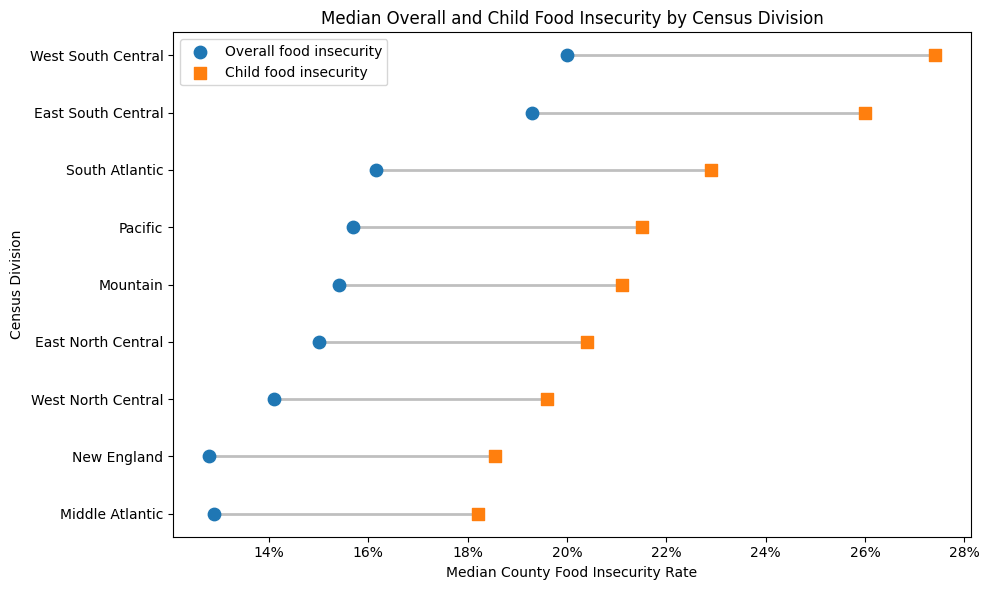

In [46]:
# Prepare Census Division medians for plotting
child_plot = (
    child_division_summary
    .reset_index()
    .sort_values("Median_Child_FI", ascending=False)
    .reset_index(drop=True)
)

# Explicit numeric y positions
y = range(len(child_plot))

fig, ax = plt.subplots(figsize=(10, 6))

# Connecting lines
for i, row in child_plot.iterrows():
    ax.plot(
        [row["Median_Overall_FI"], row["Median_Child_FI"]],
        [i, i],
        color="gray",
        linewidth=2,
        alpha=0.5,
        zorder=1
    )

# Overall food insecurity
ax.scatter(
    child_plot["Median_Overall_FI"],
    y,
    s=80,
    label="Overall food insecurity",
    zorder=3
)

# Child food insecurity
ax.scatter(
    child_plot["Median_Child_FI"],
    y,
    s=80,
    marker="s",
    label="Child food insecurity",
    zorder=3
)

# Apply division names to numeric positions
ax.set_yticks(list(y))
ax.set_yticklabels(child_plot["Census_Division"])

# Highest child FI at top
ax.invert_yaxis()

ax.set_title(
    "Median Overall and Child Food Insecurity by Census Division"
)
ax.set_xlabel("Median County Food Insecurity Rate")
ax.set_ylabel("Census Division")

ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:.0%}")
)

ax.legend()

plt.tight_layout()
plt.show()

In [47]:
state_fi_summary = (
    df.dropna(
        subset=[
            "Food_Insecurity_Rate",
            "Child_Food_Insecurity_Rate",
            "Child_FI_Gap"
        ]
    )
    .groupby(["Region", "Census_Division", "State"])
    .agg(
        Counties=("Food_Insecurity_Rate", "size"),
        Median_Overall_FI=("Food_Insecurity_Rate", "median"),
        Median_Child_FI=("Child_Food_Insecurity_Rate", "median"),
        Median_Child_Gap=("Child_FI_Gap", "median")
    )
    .reset_index()
    .sort_values("Median_Child_FI", ascending=False)
)

state_fi_summary.round(3)

,Region,Census_Division,State,Counties,Median_Overall_FI,Median_Child_FI,Median_Child_Gap
34,South,West South Central,AR,75,0.222,0.292,7.10
36,South,West South Central,OK,77,0.205,0.283,7.40
35,South,West South Central,LA,64,0.202,0.276,6.40
22,South,East South Central,KY,120,0.204,0.273,7.50
23,South,East South Central,MS,82,0.206,0.268,6.20
21,South,East South Central,AL,67,0.190,0.267,7.30
42,West,Mountain,NM,33,0.199,0.266,5.80
37,South,West South Central,TX,253,0.190,0.263,6.70
38,West,Mountain,AZ,15,0.172,0.254,7.80
28,South,South Atlantic,GA,159,0.176,0.250,7.10


#### State-Level Variation

State-level medians show that the high food insecurity observed in the South Central Census divisions is broadly distributed rather than being driven by a single state. Arkansas has the highest median child food insecurity rate at 29.2%, followed by Oklahoma at 28.3%, Louisiana at 27.6%, and Kentucky at 27.3%. Texas, despite having the largest number of counties in West South Central, has the lowest median child food insecurity rate within that division at 26.3%.

Elevated child food insecurity is not limited to the South. New Mexico and Arizona also rank among the states with the highest median county child food insecurity rates, at 26.6% and 25.4%, respectively.

Substantial variation also exists within Census divisions. In West North Central, for example, median child food insecurity ranges from 16.5% in North Dakota to 22.7% in Missouri. This within-division variation reinforces the value of allowing users to move from Census Division to state and county when interpreting geographic patterns.

The additional burden among children also varies by state. While child food insecurity exceeds overall food insecurity nearly universally at the county level, state median gaps range from 2.9 percentage points in Rhode Island to 7.8 percentage points in Arizona.

In [48]:
metro_summary = (
    df.dropna(
        subset=[
            "Metro_Status",
            "ESI_C",
            "Food_Insecurity_Rate",
            "Child_Food_Insecurity_Rate",
            "Child_FI_Gap"
        ]
    )
    .groupby("Metro_Status")
    .agg(
        Counties=("FIPS", "size"),
        Median_ESI=("ESI_C", "median"),
        Median_Overall_FI=("Food_Insecurity_Rate", "median"),
        Median_Child_FI=("Child_Food_Insecurity_Rate", "median"),
        Median_Child_Gap=("Child_FI_Gap", "median")
    )
)

metro_summary.round(3)

,Counties,Median_ESI,Median_Overall_FI,Median_Child_FI,Median_Child_Gap
Metro_Status,,,,,
Metropolitan,1185,48.149,0.149,0.201,5.3
Nonmetropolitan,1957,52.407,0.169,0.233,6.2


In [49]:
metro_distribution = (
    df.dropna(subset=["Metro_Status"])
    .groupby("Metro_Status")
    .agg(
        Counties=("FIPS", "size"),
        ESI_Q1=("ESI_C", lambda x: x.quantile(0.25)),
        ESI_Median=("ESI_C", "median"),
        ESI_Q3=("ESI_C", lambda x: x.quantile(0.75)),
        FI_Q1=("Food_Insecurity_Rate", lambda x: x.quantile(0.25)),
        FI_Median=("Food_Insecurity_Rate", "median"),
        FI_Q3=("Food_Insecurity_Rate", lambda x: x.quantile(0.75)),
        Child_FI_Q1=("Child_Food_Insecurity_Rate", lambda x: x.quantile(0.25)),
        Child_FI_Median=("Child_Food_Insecurity_Rate", "median"),
        Child_FI_Q3=("Child_Food_Insecurity_Rate", lambda x: x.quantile(0.75))
    )
)

metro_distribution.round(3)

,Counties,ESI_Q1,ESI_Median,ESI_Q3,FI_Q1,FI_Median,FI_Q3,Child_FI_Q1,Child_FI_Median,Child_FI_Q3
Metro_Status,,,,,,,,,,
Metropolitan,1186,34.479,48.149,61.512,0.126,0.149,0.173,0.171,0.201,0.240
Nonmetropolitan,1958,33.551,52.407,67.961,0.143,0.169,0.197,0.198,0.233,0.271


In [50]:
metro_tail = (
    df.dropna(
        subset=[
            "Metro_Status",
            "Food_Insecurity_Rate",
            "Child_Food_Insecurity_Rate"
        ]
    )
    .groupby("Metro_Status")
    .agg(
        Counties=("FIPS", "size"),
        Overall_FI_Top20=("Food_Insecurity_Rate",
                          lambda x: (x >= fi_80).sum()),
        Child_FI_Top20=("Child_Food_Insecurity_Rate",
                        lambda x: (x >= child_fi_80).sum())
    )
)

metro_tail["Overall_FI_Top20_Pct"] = (
    metro_tail["Overall_FI_Top20"]
    / metro_tail["Counties"] * 100
)

metro_tail["Child_FI_Top20_Pct"] = (
    metro_tail["Child_FI_Top20"]
    / metro_tail["Counties"] * 100
)

metro_tail.round(2)

,Counties,Overall_FI_Top20,Child_FI_Top20,Overall_FI_Top20_Pct,Child_FI_Top20_Pct
Metro_Status,,,,,
Metropolitan,1185,117,130,9.87,10.97
Nonmetropolitan,1957,513,504,26.21,25.75


#### Metropolitan and Nonmetropolitan Counties

Nationally, nonmetropolitan counties show higher levels of economic stress and food insecurity than metropolitan counties. Median overall food insecurity is 16.9% among nonmetropolitan counties compared with 14.9% among metropolitan counties, while median child food insecurity is 23.3% compared with 20.1%.

The difference is particularly apparent in the upper tail of the national distribution. Approximately 26.2% of nonmetropolitan counties fall within the highest national quintile of overall food insecurity, compared with 9.9% of metropolitan counties. A similar pattern appears for child food insecurity, with 25.8% of nonmetropolitan counties and 11.0% of metropolitan counties falling within the highest national quintile.

The median child food insecurity gap is also larger among nonmetropolitan counties: 6.2 percentage points compared with 5.3 percentage points among metropolitan counties.

These national differences should not be interpreted as the effect of metropolitan status alone. Because both food insecurity and metropolitan status may vary geographically, comparisons within Census divisions are needed to distinguish the national metro/nonmetro pattern from regional composition.

In [51]:
division_metro_summary = (
    df.dropna(
        subset=[
            "Census_Division",
            "Metro_Status",
            "ESI_C",
            "Food_Insecurity_Rate",
            "Child_Food_Insecurity_Rate",
            "Child_FI_Gap"
        ]
    )
    .groupby(["Region", "Census_Division", "Metro_Status"])
    .agg(
        Counties=("FIPS", "size"),
        Median_ESI=("ESI_C", "median"),
        Median_Overall_FI=("Food_Insecurity_Rate", "median"),
        Median_Child_FI=("Child_Food_Insecurity_Rate", "median"),
        Median_Child_Gap=("Child_FI_Gap", "median")
    )
    .reset_index()
)

division_metro_summary.round(3)

,Region,Census_Division,Metro_Status,Counties,Median_ESI,Median_Overall_FI,Median_Child_FI,Median_Child_Gap
0,Midwest,East North Central,Metropolitan,179,39.294,0.143,0.188,4.70
1,Midwest,East North Central,Nonmetropolitan,258,44.040,0.155,0.212,5.60
2,Midwest,West North Central,Metropolitan,131,29.510,0.129,0.179,4.70
3,Midwest,West North Central,Nonmetropolitan,487,31.393,0.143,0.201,5.60
4,Northeast,Middle Atlantic,Metropolitan,91,48.786,0.125,0.173,5.00
5,Northeast,Middle Atlantic,Nonmetropolitan,59,54.900,0.136,0.193,5.80
6,Northeast,New England,Metropolitan,34,39.230,0.126,0.172,4.60
7,Northeast,New England,Nonmetropolitan,34,39.530,0.134,0.189,6.00
8,South,East South Central,Metropolitan,134,54.022,0.176,0.243,6.05
9,South,East South Central,Nonmetropolitan,230,67.990,0.202,0.268,6.70


In [52]:
division_metro_pivot = (
    division_metro_summary
    .pivot(
        index=["Region", "Census_Division"],
        columns="Metro_Status",
        values=[
            "Median_Overall_FI",
            "Median_Child_FI",
            "Median_Child_Gap"
        ]
    )
)

division_metro_pivot["Overall_FI_Difference"] = (
    division_metro_pivot["Median_Overall_FI"]["Nonmetropolitan"]
    - division_metro_pivot["Median_Overall_FI"]["Metropolitan"]
)

division_metro_pivot["Child_FI_Difference"] = (
    division_metro_pivot["Median_Child_FI"]["Nonmetropolitan"]
    - division_metro_pivot["Median_Child_FI"]["Metropolitan"]
)

division_metro_pivot["Child_Gap_Difference"] = (
    division_metro_pivot["Median_Child_Gap"]["Nonmetropolitan"]
    - division_metro_pivot["Median_Child_Gap"]["Metropolitan"]
)

division_metro_pivot.round(3)

Median_Overall_FI                  \
Metro_Status                      Metropolitan Nonmetropolitan   
Region    Census_Division                                        
Midwest   East North Central             0.143           0.155   
          West North Central             0.129           0.143   
Northeast Middle Atlantic                0.125           0.136   
          New England                    0.126           0.134   
South     East South Central             0.176           0.202   
          South Atlantic                 0.145           0.175   
          West South Central             0.182           0.209   
West      Mountain                       0.141           0.160   
          Pacific                        0.144           0.161   

                             Median_Child_FI                 Median_Child_Gap  \
Metro_Status                    Metropolitan Nonmetropolitan     Metropolitan   
Region    Census_Division                                                       
Midwest   East North Central           0.188           0.212             4.70   
          West North Central           0.179           0.201             4.70   
Northeast Middle Atlantic              0.173           0.193             5.00   
          New England                  0.172           0.189             4.60   
South     East South Central           0.243           0.268             6.05   
          South Atlantic               0.204           0.251             5.60   
          West South Central           0.250           0.285             6.10   
West      Mountain                     0.192           0.218             5.10   
          Pacific                      0.198           0.229             5.10   

                                             Overall_FI_Difference  \
Metro_Status                 Nonmetropolitan                         
Region    Census_Division                                            
Midwest   East North Central             5.6                 0.012   
          West North Central             5.6                 0.014   
Northeast Middle Atlantic                5.8                 0.011   
          New England                    6.0                 0.008   
South     East South Central             6.7                 0.027   
          South Atlantic                 7.6                 0.030   
          West South Central             7.5                 0.026   
West      Mountain                       5.9                 0.019   
          Pacific                        6.4                 0.017   

                             Child_FI_Difference Child_Gap_Difference  
Metro_Status                                                           
Region    Census_Division                                              
Midwest   East North Central               0.024                 0.90  
          West North Central               0.022                 0.90  
Northeast Middle Atlantic                  0.020                 0.80  
          New England                      0.017                 1.40  
South     East South Central               0.026                 0.65  
          South Atlantic                   0.047                 2.00  
          West South Central               0.035                 1.40  
West      Mountain                         0.026                 0.80  
          Pacific                          0.030                 1.30

#### Metro and Nonmetro Differences Within Census Divisions

The national metro/nonmetro food insecurity difference persists within every U.S. Census division. Across all nine divisions, nonmetropolitan counties have higher median overall food insecurity, higher median child food insecurity, and larger median child food insecurity gaps than metropolitan counties.

The magnitude of these differences varies geographically. South Atlantic shows the largest metro/nonmetro separation in child food insecurity: the median is 20.4% among metropolitan counties and 25.1% among nonmetropolitan counties, a difference of 4.7 percentage points. Its median child food insecurity gap also increases from 5.6 percentage points in metropolitan counties to 7.6 points in nonmetropolitan counties.

Elevated food insecurity in the South Central divisions is not limited to nonmetropolitan counties. In West South Central, median child food insecurity is 25.0% among metropolitan counties and 28.5% among nonmetropolitan counties. In East South Central, the corresponding medians are 24.3% and 26.8%. Nonmetropolitan counties experience still higher burden, but both groups have elevated food insecurity relative to national county distributions.

In eight of the nine Census divisions, the metro/nonmetro difference is larger for child food insecurity than for overall food insecurity. Taken together, these descriptive results indicate that metropolitan status and geographic location capture overlapping but distinct patterns in county food insecurity.

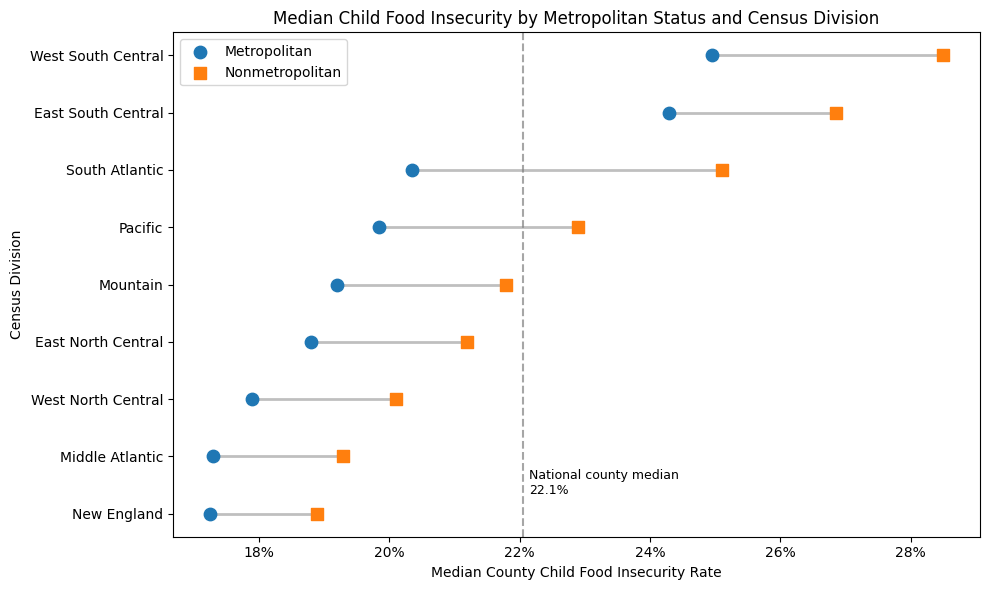

In [54]:
# Prepare metro/nonmetro child FI medians by Census Division

metro_child_plot = (
    division_metro_summary
    .pivot(
        index="Census_Division",
        columns="Metro_Status",
        values="Median_Child_FI"
    )
    .dropna()
    .reset_index()
)

# Order by nonmetropolitan child FI, highest to lowest
metro_child_plot = (
    metro_child_plot
    .sort_values("Nonmetropolitan", ascending=False)
    .reset_index(drop=True)
)

# Explicit numeric y positions
y = range(len(metro_child_plot))

fig, ax = plt.subplots(figsize=(10, 6))

# Connecting lines
for i, row in metro_child_plot.iterrows():
    ax.plot(
        [row["Metropolitan"], row["Nonmetropolitan"]],
        [i, i],
        color="gray",
        linewidth=2,
        alpha=0.5,
        zorder=1
    )

# Metropolitan counties
ax.scatter(
    metro_child_plot["Metropolitan"],
    y,
    s=80,
    label="Metropolitan",
    zorder=3
)

# Nonmetropolitan counties
ax.scatter(
    metro_child_plot["Nonmetropolitan"],
    y,
    s=80,
    marker="s",
    label="Nonmetropolitan",
    zorder=3
)

# National median child food insecurity
national_child_fi_median = df["Child_Food_Insecurity_Rate"].median()

ax.axvline(
    national_child_fi_median,
    linestyle="--",
    linewidth=1.5,
    color="gray",
    alpha=0.7
)

ax.text(
    national_child_fi_median + 0.001,
    7.7,
    f"National county median\n{national_child_fi_median:.1%}",
    fontsize=9,
    va="bottom"
)

# Census Division labels
ax.set_yticks(list(y))
ax.set_yticklabels(metro_child_plot["Census_Division"])

# Highest nonmetro child FI at top
ax.invert_yaxis()

ax.set_title(
    "Median Child Food Insecurity by Metropolitan Status and Census Division"
)
ax.set_xlabel("Median County Child Food Insecurity Rate")
ax.set_ylabel("Census Division")

ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:.0%}")
)

ax.legend()

plt.tight_layout()
plt.show()

In [55]:
# Predicted food insecurity from the ESI v2 regression
df["Predicted_FI"] = (
    result.intercept +
    result.slope * df["ESI_C"]
)

# Residual = observed FI - predicted FI
df["FI_Residual"] = (
    df["Food_Insecurity_Rate"] -
    df["Predicted_FI"]
)

# Express residual in percentage points for easier interpretation
df["FI_Residual_PP"] = df["FI_Residual"] * 100

In [56]:
df["FI_Residual_PP"].describe()

count    3.142000e+03
mean     1.121672e-15
std      2.998172e+00
min     -1.098870e+01
25%     -2.015413e+00
50%     -1.674429e-01
75%      1.825854e+00
max      1.797322e+01
Name: FI_Residual_PP, dtype: float64

In [57]:
print(f"Mean residual: {df['FI_Residual_PP'].mean():.4f} percentage points")
print(f"Median residual: {df['FI_Residual_PP'].median():.2f} percentage points")
print(f"Standard deviation: {df['FI_Residual_PP'].std():.2f} percentage points")
print(f"Minimum residual: {df['FI_Residual_PP'].min():.2f} percentage points")
print(f"Maximum residual: {df['FI_Residual_PP'].max():.2f} percentage points")

Mean residual: 0.0000 percentage points
Median residual: -0.17 percentage points
Standard deviation: 3.00 percentage points
Minimum residual: -10.99 percentage points
Maximum residual: 17.97 percentage points


In [58]:
higher_than_predicted = (
    df[
        [
            "FIPS",
            "State",
            "County",
            "Metro_Status",
            "Census_Division",
            "ESI_C",
            "Food_Insecurity_Rate",
            "Predicted_FI",
            "FI_Residual_PP"
        ]
    ]
    .dropna()
    .sort_values("FI_Residual_PP", ascending=False)
    .head(20)
)

higher_than_predicted.round(3)

,FIPS,State,County,Metro_Status,Census_Division,ESI_C,Food_Insecurity_Rate,Predicted_FI,FI_Residual_PP
2655,48261,TX,Kenedy County,Nonmetropolitan,West South Central,52.985,0.347,0.167,17.973
2588,48127,TX,Dimmit County,Nonmetropolitan,West South Central,79.945,0.371,0.201,16.953
2590,48131,TX,Duval County,Nonmetropolitan,West South Central,64.280,0.329,0.182,14.740
2778,48507,TX,Zavala County,Nonmetropolitan,West South Central,70.607,0.337,0.190,14.738
2777,48505,TX,Zapata County,Nonmetropolitan,West South Central,76.912,0.334,0.198,13.638
2713,48377,TX,Presidio County,Nonmetropolitan,West South Central,55.122,0.305,0.170,13.502
2738,48427,TX,Starr County,Nonmetropolitan,West South Central,86.266,0.344,0.209,13.451
2548,48047,TX,Brooks County,Nonmetropolitan,West South Central,55.488,0.304,0.170,13.356
1089,21189,KY,Owsley County,Nonmetropolitan,East South Central,80.496,0.321,0.202,11.883
2564,48079,TX,Cochran County,Metropolitan,West South Central,60.802,0.288,0.177,11.082


In [59]:
lower_than_predicted = (
    df[
        [
            "FIPS",
            "State",
            "County",
            "Metro_Status",
            "Census_Division",
            "ESI_C",
            "Food_Insecurity_Rate",
            "Predicted_FI",
            "FI_Residual_PP"
        ]
    ]
    .dropna()
    .sort_values("FI_Residual_PP")
    .head(20)
)

lower_than_predicted.round(3)

,FIPS,State,County,Metro_Status,Census_Division,ESI_C,Food_Insecurity_Rate,Predicted_FI,FI_Residual_PP
2861,51081,VA,Greensville County,Nonmetropolitan,South Atlantic,94.459,0.110,0.220,-10.989
1177,22125,LA,West Feliciana Parish,Metropolitan,West South Central,97.083,0.126,0.223,-9.722
2909,51183,VA,Sussex County,Metropolitan,South Atlantic,75.793,0.106,0.196,-9.020
2834,51025,VA,Brunswick County,Nonmetropolitan,South Atlantic,76.397,0.109,0.197,-8.797
323,12003,FL,Baker County,Metropolitan,South Atlantic,74.319,0.108,0.194,-8.633
1859,36059,NY,Nassau County,Metropolitan,Middle Atlantic,41.107,0.071,0.152,-8.120
386,12129,FL,Wakulla County,Metropolitan,South Atlantic,55.934,0.092,0.171,-7.901
2891,51145,VA,Powhatan County,Metropolitan,South Atlantic,40.826,0.075,0.152,-7.684
2905,51175,VA,Southampton County,Nonmetropolitan,South Atlantic,70.002,0.114,0.189,-7.486
325,12007,FL,Bradford County,Nonmetropolitan,South Atlantic,92.003,0.142,0.217,-7.477


In [60]:
resid_sd = df["FI_Residual_PP"].std()

upper_resid = 2 * resid_sd
lower_resid = -2 * resid_sd

print(f"+2 SD threshold: {upper_resid:.2f} percentage points")
print(f"-2 SD threshold: {lower_resid:.2f} percentage points")

df["FI_Residual_Flag"] = np.select(
    [
        df["FI_Residual_PP"] >= upper_resid,
        df["FI_Residual_PP"] <= lower_resid
    ],
    [
        "Higher FI than predicted",
        "Lower FI than predicted"
    ],
    default="Within ±2 SD"
)

df["FI_Residual_Flag"].value_counts()

+2 SD threshold: 6.00 percentage points
-2 SD threshold: -6.00 percentage points


FI_Residual_Flag
Within ±2 SD                3013
Higher FI than predicted      89
Lower FI than predicted       42
Name: count, dtype: int64

In [61]:
residual_state_summary = (
    df[df["FI_Residual_Flag"] != "Within ±2 SD"]
    .groupby(["State", "FI_Residual_Flag"])
    .size()
    .unstack(fill_value=0)
)

residual_state_summary["Total_Flagged"] = residual_state_summary.sum(axis=1)

residual_state_summary = (
    residual_state_summary
    .sort_values("Total_Flagged", ascending=False)
)

residual_state_summary.head(20)

FI_Residual_Flag,Higher FI than predicted,Lower FI than predicted,Total_Flagged
State,,,
TX,41,0,41
VA,0,13,13
AR,12,0,12
KY,8,0,8
CA,1,6,7
NY,0,6,6
FL,0,5,5
ND,0,5,5
SD,4,0,4


In [62]:
state_counties = (
    df.dropna(subset=["FI_Residual_PP"])
    .groupby("State")
    .size()
    .rename("Counties")
)

state_residual_rates = (
    residual_state_summary
    .join(state_counties)
)

state_residual_rates["Flagged_Pct"] = (
    state_residual_rates["Total_Flagged"]
    / state_residual_rates["Counties"]
    * 100
)

state_residual_rates = (
    state_residual_rates
    .sort_values("Flagged_Pct", ascending=False)
)

state_residual_rates.head(20).round(2)

,Higher FI than predicted,Lower FI than predicted,Total_Flagged,Counties,Flagged_Pct
State,,,,,
TX,41,0,41,253,16.21
AR,12,0,12,75,16.00
CA,1,6,7,58,12.07
VA,0,13,13,133,9.77
NY,0,6,6,62,9.68
ND,0,5,5,53,9.43
NM,3,0,3,33,9.09
FL,0,5,5,67,7.46
MA,0,1,1,14,7.14


In [63]:
residual_division_summary = (
    df.dropna(subset=["FI_Residual_PP"])
    .groupby(["Region", "Census_Division"])
    .agg(
        Counties=("FIPS", "size"),
        Median_Residual_PP=("FI_Residual_PP", "median"),
        Mean_Residual_PP=("FI_Residual_PP", "mean"),
        Higher_2SD=(
            "FI_Residual_Flag",
            lambda x: (x == "Higher FI than predicted").sum()
        ),
        Lower_2SD=(
            "FI_Residual_Flag",
            lambda x: (x == "Lower FI than predicted").sum()
        )
    )
)

residual_division_summary["Higher_2SD_Pct"] = (
    residual_division_summary["Higher_2SD"]
    / residual_division_summary["Counties"]
    * 100
)

residual_division_summary["Lower_2SD_Pct"] = (
    residual_division_summary["Lower_2SD"]
    / residual_division_summary["Counties"]
    * 100
)

residual_division_summary.sort_values(
    "Median_Residual_PP",
    ascending=False
).round(2)

Counties  Median_Residual_PP  Mean_Residual_PP  \
Region    Census_Division                                                      
South     West South Central       469                2.60              2.68   
          East South Central       364                1.18              1.41   
Midwest   West North Central       618                0.08              0.13   
West      Mountain                 281               -0.08             -0.07   
Midwest   East North Central       437               -0.34             -0.36   
South     South Atlantic           588               -1.44             -1.42   
West      Pacific                  167               -1.47             -1.12   
Northeast New England               68               -2.14             -2.10   
          Middle Atlantic          150               -3.48             -3.38   

                              Higher_2SD  Lower_2SD  Higher_2SD_Pct  \
Region    Census_Division                                             
South     West South Central          58          1           12.37   
          East South Central          13          0            3.57   
Midwest   West North Central           9          6            1.46   
West      Mountain                     4          1            1.42   
Midwest   East North Central           0          0            0.00   
South     South Atlantic               2         18            0.34   
West      Pacific                      3          6            1.80   
Northeast New England                  0          1            0.00   
          Middle Atlantic              0          9            0.00   

                              Lower_2SD_Pct  
Region    Census_Division                    
South     West South Central           0.21  
          East South Central           0.00  
Midwest   West North Central           0.97  
West      Mountain                     0.36  
Midwest   East North Central           0.00  
South     South Atlantic               3.06  
West      Pacific                      3.59  
Northeast New England                  1.47  
          Middle Atlantic              6.00

#### Geographic Pattern in Food Insecurity Residuals

Residual analysis shows that the relationship between ESI v2 and food insecurity varies systematically across U.S. Census divisions. Positive residuals indicate food insecurity rates higher than predicted by the national ESI–food insecurity regression, while negative residuals indicate rates lower than predicted.

West South Central shows the largest positive shift. Its median residual is +2.60 percentage points and its mean residual is +2.68 points, indicating that food insecurity is typically higher than the national ESI relationship predicts. Approximately 12.4% of counties in the division are at least two residual standard deviations above prediction, compared with only 0.2% at least two standard deviations below.

East South Central also shows a positive shift, with a median residual of +1.18 percentage points. In contrast, several divisions tend to fall below the national regression prediction. Middle Atlantic has the largest negative median residual at -3.48 percentage points, followed by New England at -2.14 points, Pacific at -1.47 points, and South Atlantic at -1.44 points.

These results indicate that ESI and food insecurity have a meaningful national relationship, but a single national regression does not fully capture geographic differences in food insecurity outcomes. Census divisions differ not only in their typical levels of economic stress and food insecurity, but also in where their counties tend to fall relative to the national ESI–food insecurity relationship.

In [64]:
residual_profile = (
    df.dropna(subset=["FI_Residual_Flag"])
    .groupby("FI_Residual_Flag")
    .agg(
        Counties=("FIPS", "size"),
        Median_ESI=("ESI_C", "median"),
        Median_FI=("Food_Insecurity_Rate", "median"),
        Median_Child_FI=("Child_Food_Insecurity_Rate", "median"),
        Median_Child_Gap=("Child_FI_Gap", "median"),
        Median_Poverty=("Poverty_All_Pct", "median"),
        Median_NonWork=("Prime_Age_Did_Not_Work_Pct", "median"),
        Median_Housing=("Severe_Burden_Pct", "median"),
        Median_MHI=("Median_Household_Income", "median"),
        Median_Uninsured=("Uninsured_Rate", "median")
    )
)

# Put the groups in an intuitive order
residual_profile = residual_profile.reindex([
    "Higher FI than predicted",
    "Within ±2 SD",
    "Lower FI than predicted"
])

residual_profile.round(2)

,Counties,Median_ESI,Median_FI,Median_Child_FI,Median_Child_Gap,Median_Poverty,Median_NonWork,Median_Housing,Median_MHI,Median_Uninsured
FI_Residual_Flag,,,,,,,,,,
Higher FI than predicted,89,64.13,0.26,0.32,6.40,20.00,22.97,12.55,52075.0,15.4
Within ±2 SD,3013,50.01,0.16,0.22,5.90,13.10,16.86,17.85,67024.0,9.7
Lower FI than predicted,42,51.38,0.10,0.15,4.95,11.35,16.84,25.46,82549.5,6.3


In [65]:
insurance_relationships = df[
    [
        "Uninsured_Rate",
        "Food_Insecurity_Rate",
        "Child_Food_Insecurity_Rate",
        "ESI_C",
        "Poverty_All_Pct",
        "Median_Household_Income"
    ]
].corr(method="pearson")

insurance_relationships.round(3)

,Uninsured_Rate,Food_Insecurity_Rate,Child_Food_Insecurity_Rate,ESI_C,Poverty_All_Pct,Median_Household_Income
Uninsured_Rate,1.000,0.505,0.443,0.266,0.327,-0.329
Food_Insecurity_Rate,0.505,1.000,0.884,0.652,0.740,-0.692
Child_Food_Insecurity_Rate,0.443,0.884,1.000,0.648,0.760,-0.724
ESI_C,0.266,0.652,0.648,1.000,0.769,-0.588
Poverty_All_Pct,0.327,0.740,0.760,0.769,1.000,-0.768
Median_Household_Income,-0.329,-0.692,-0.724,-0.588,-0.768,1.000


In [66]:
insurance_spearman = df[
    [
        "Uninsured_Rate",
        "Food_Insecurity_Rate",
        "Child_Food_Insecurity_Rate",
        "ESI_C",
        "Poverty_All_Pct",
        "Median_Household_Income"
    ]
].corr(method="spearman")

insurance_spearman.round(3)

,Uninsured_Rate,Food_Insecurity_Rate,Child_Food_Insecurity_Rate,ESI_C,Poverty_All_Pct,Median_Household_Income
Uninsured_Rate,1.000,0.557,0.513,0.312,0.416,-0.393
Food_Insecurity_Rate,0.557,1.000,0.897,0.672,0.781,-0.752
Child_Food_Insecurity_Rate,0.513,0.897,1.000,0.665,0.786,-0.762
ESI_C,0.312,0.672,0.665,1.000,0.826,-0.670
Poverty_All_Pct,0.416,0.781,0.786,0.826,1.000,-0.880
Median_Household_Income,-0.393,-0.752,-0.762,-0.670,-0.880,1.000


#### Uninsured Rate as Additional Context

Uninsured rate provides additional context for understanding differences between economic stress and food insecurity. Nationally, uninsured rate has a moderate positive relationship with overall food insecurity (Pearson r = 0.505; Spearman ρ = 0.557) and child food insecurity (Pearson r = 0.443; Spearman ρ = 0.513). Its relationship with ESI is considerably weaker (Pearson r = 0.266; Spearman ρ = 0.312).

The residual analysis reinforces this distinction. Counties with food insecurity rates substantially higher than predicted by ESI have a median uninsured rate of 15.4%, compared with 9.7% among counties within ±2 residual standard deviations and 6.3% among counties with food insecurity substantially below prediction.

These findings do not establish that lack of health insurance causes higher food insecurity, nor do they establish that insurance coverage independently explains differences between observed and predicted food insecurity. Geographic, income, poverty, policy, and other socioeconomic factors may contribute to both measures. However, the results indicate that uninsured rate captures relevant county-level context that is not strongly represented by ESI alone.

For this reason, uninsured rate is retained as a contextual indicator rather than incorporated into the ESI. ESI is intended to describe multidimensional economic stress, while food insecurity and related contextual measures provide complementary information about how economic conditions are experienced across counties.